# Confidence analysis
## Three run-1 models: ResNet18 224, ResNet50 28 and original ViT; full test split

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.90, 10
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)


3421 test images; high-confidence threshold: 90%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


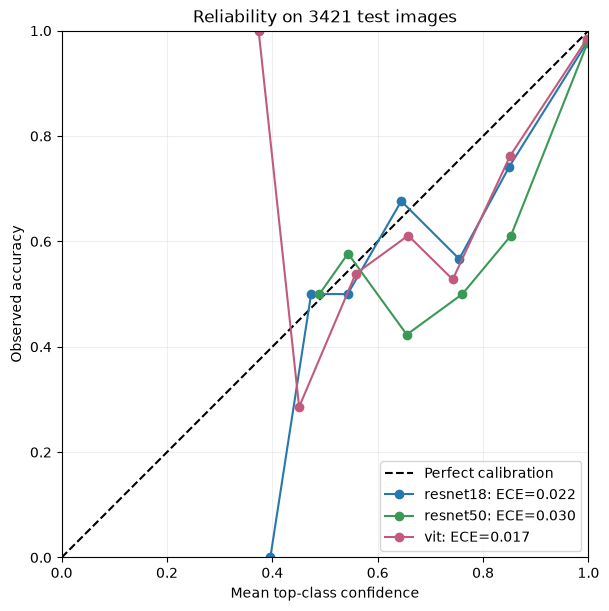

In [2]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## Top-class confidence — all models overlaid, aggregated across classes; all correct and all incorrect test predictions

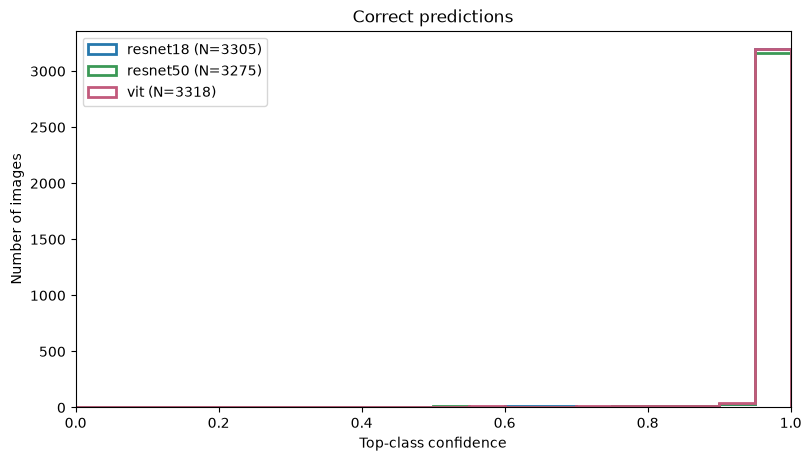

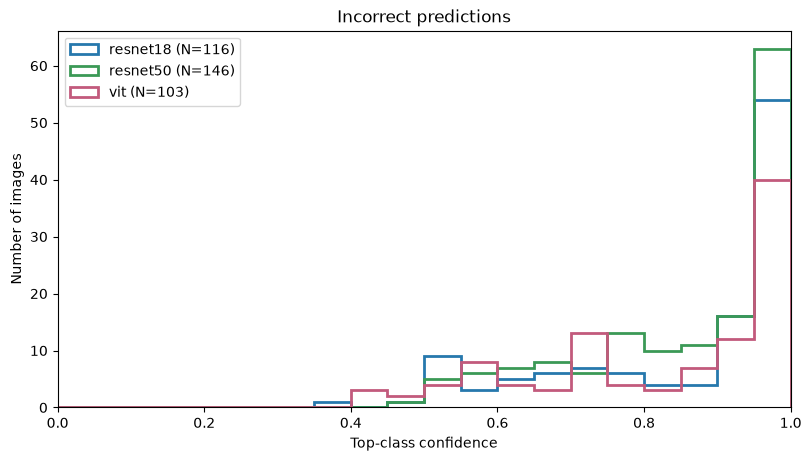

In [3]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    for m, color in enumerate(model_colors):
        mask = correct[m] == is_correct
        ax.hist(confidence[m, mask], bins=np.linspace(0, 1, 21), histtype='step',
                linewidth=2, color=color, label=f'{model_names[m]} (N={mask.sum()})')
    ax.set(title=title, xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    ax.legend()
    plt.show()

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

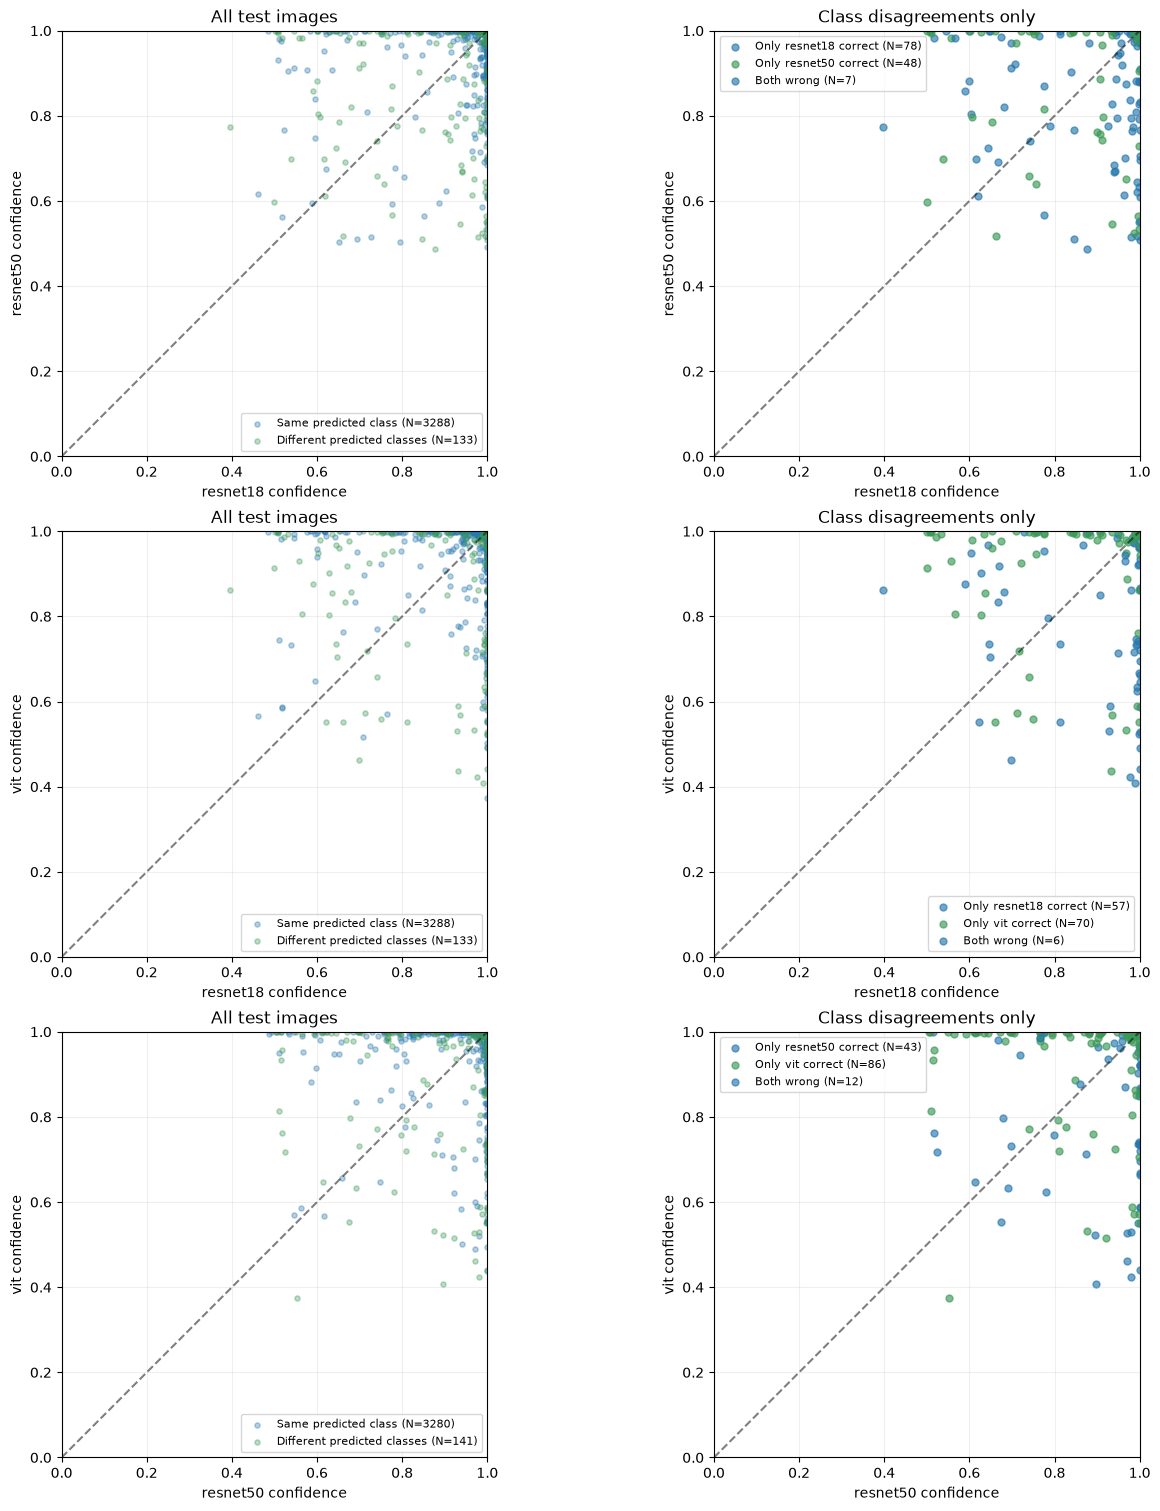

In [4]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 5 * len(pairs)), layout='constrained')
for row, (i, j) in enumerate(pairs):
    agree = predicted[i] == predicted[j]
    for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
        axes[row, 0].scatter(confidence[i, mask], confidence[j, mask], s=14, alpha=0.35,
                              color=color, label=f'{title} (N={mask.sum()})')
    groups = [(correct[i] & ~correct[j], 'C0', f'Only {model_names[i]} correct'),
              (~correct[i] & correct[j], 'C1', f'Only {model_names[j]} correct'),
              (~correct[i] & ~correct[j], 'C3', 'Both wrong')]
    for mask, color, title in groups:
        mask = mask & ~agree
        axes[row, 1].scatter(confidence[i, mask], confidence[j, mask], s=25, alpha=0.65,
                              color=color, label=f'{title} (N={mask.sum()})')
    for ax, title in zip(axes[row], ['All test images', 'Class disagreements only']):
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        ax.set(title=title, xlabel=f'{model_names[i]} confidence', ylabel=f'{model_names[j]} confidence',
               xlim=(0, 1), ylim=(0, 1))
        ax.set_aspect('equal')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.show()


## Predictive entropy — normalized to [0, 1]; correct/error distributions and empirical error rate by entropy bin, with image counts

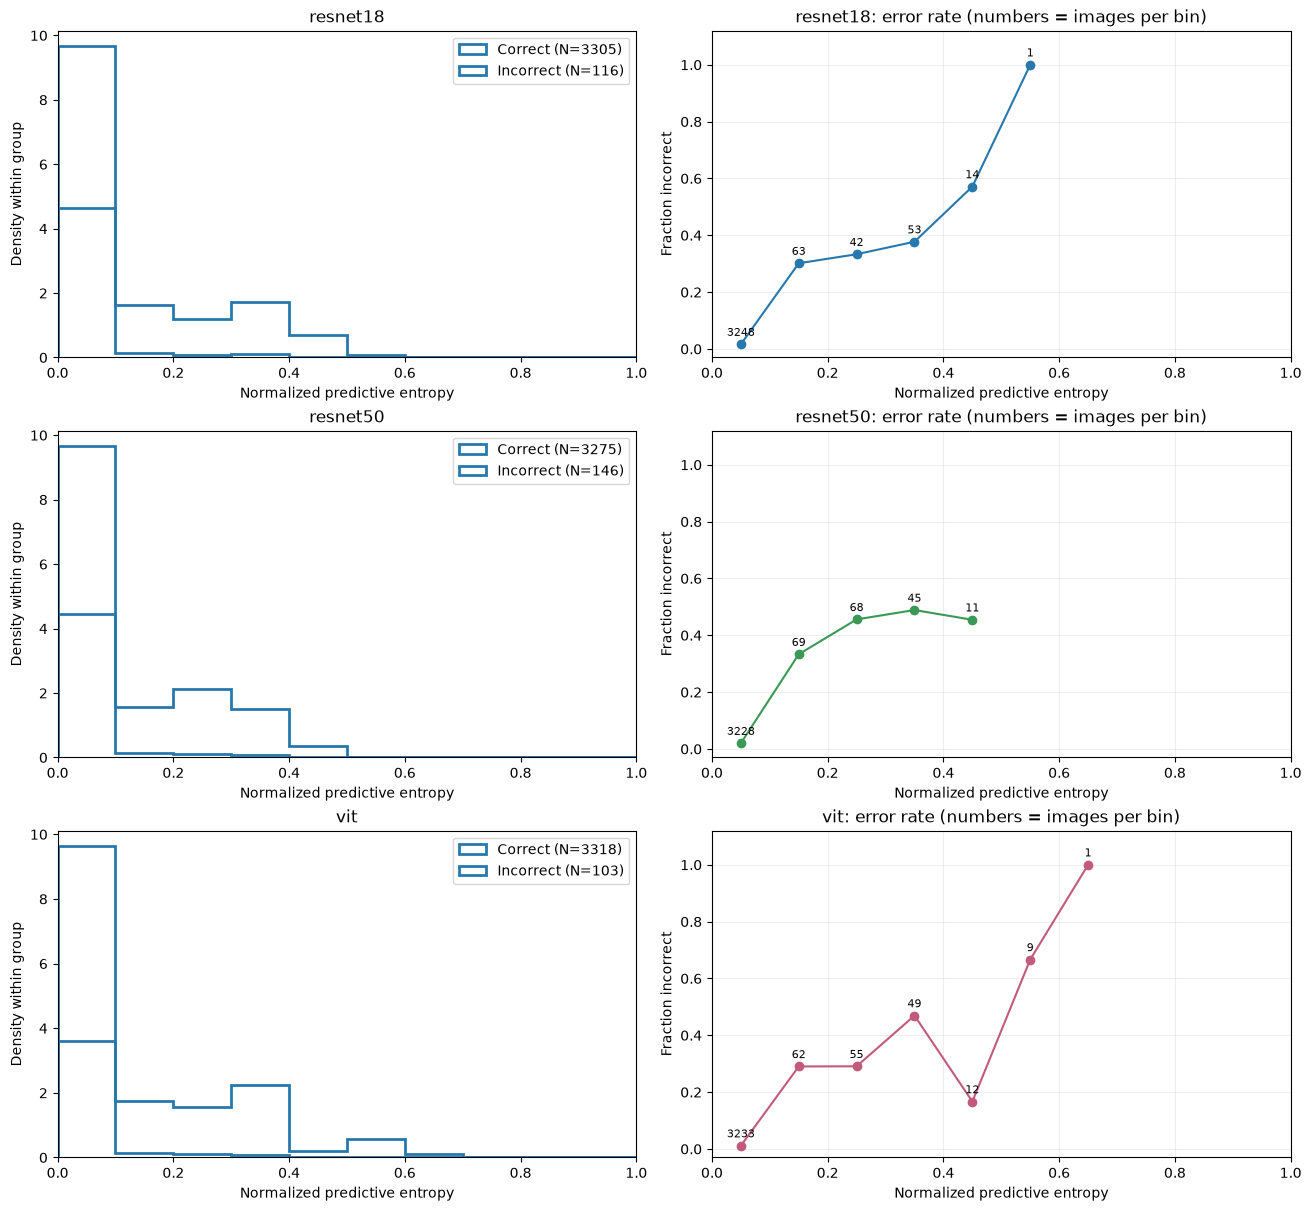

In [5]:
fig, axes = plt.subplots(len(model_names), 2, figsize=(13, 4 * len(model_names)), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], 'C0', 'Correct'), (~correct[m], 'C3', 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=name, xlabel='Normalized predictive entropy', ylabel='Density within group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins)
    rates = np.divide(errors, counts, out=np.full(n_bins, np.nan), where=counts > 0)
    axes[m, 1].plot(centers, rates, 'o-', color=f'C{m}')
    for x, y, n in zip(centers, rates, counts):
        if n:
            axes[m, 1].annotate(str(n), (x, y), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8)
    axes[m, 1].set(title=f'{name}: error rate (numbers = images per bin)',
                   xlabel='Normalized predictive entropy', ylabel='Fraction incorrect', xlim=(0, 1), ylim=(-0.03, 1.12))
    axes[m, 1].grid(alpha=0.2)
plt.show()

## Confidence under transformations — same 320-image stability subset; average noise repeats within each image; dashed lines show baseline

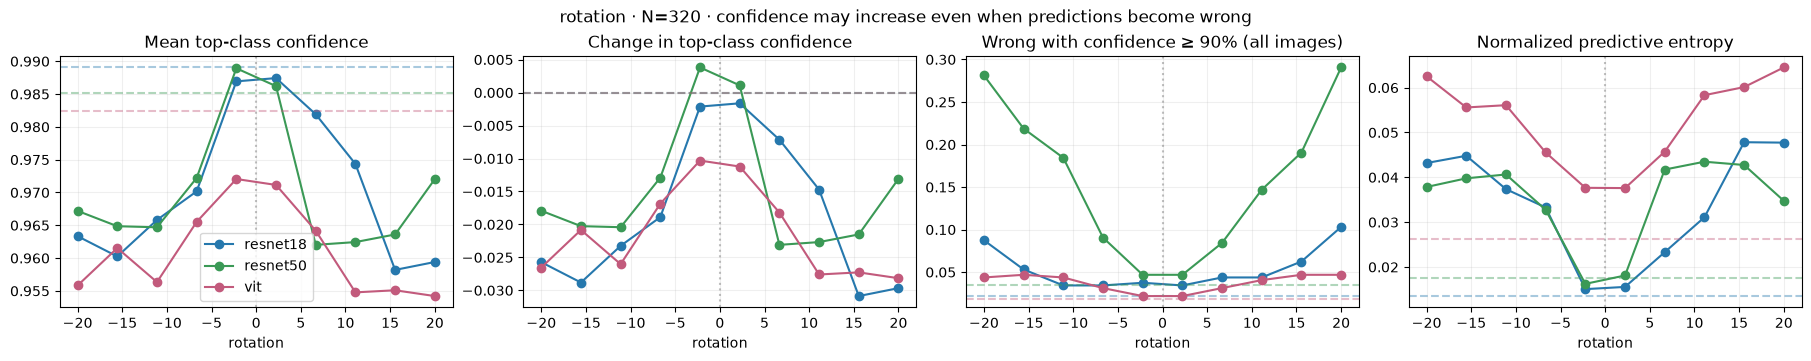

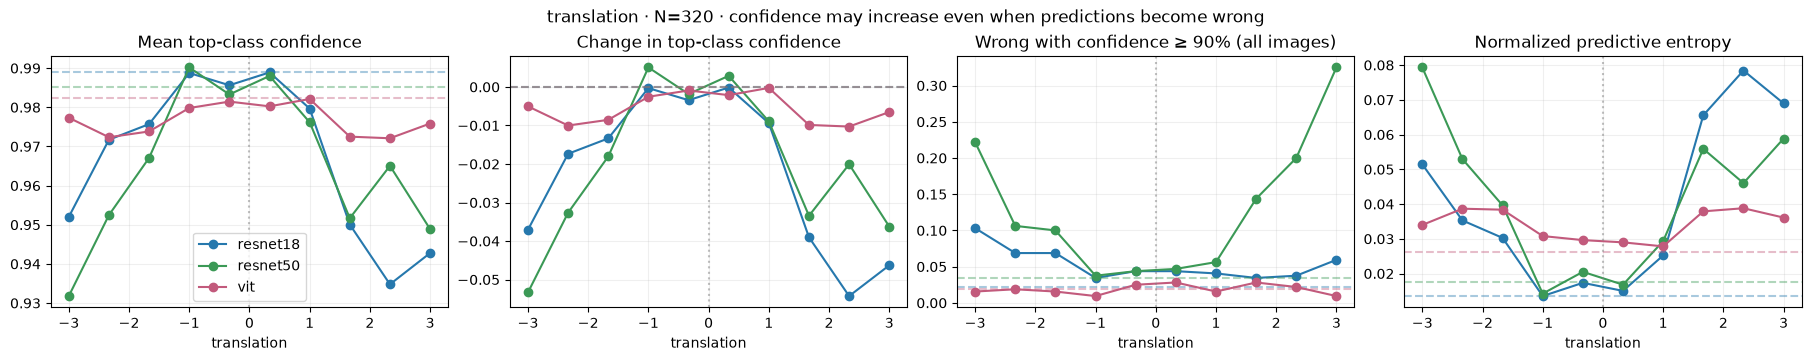

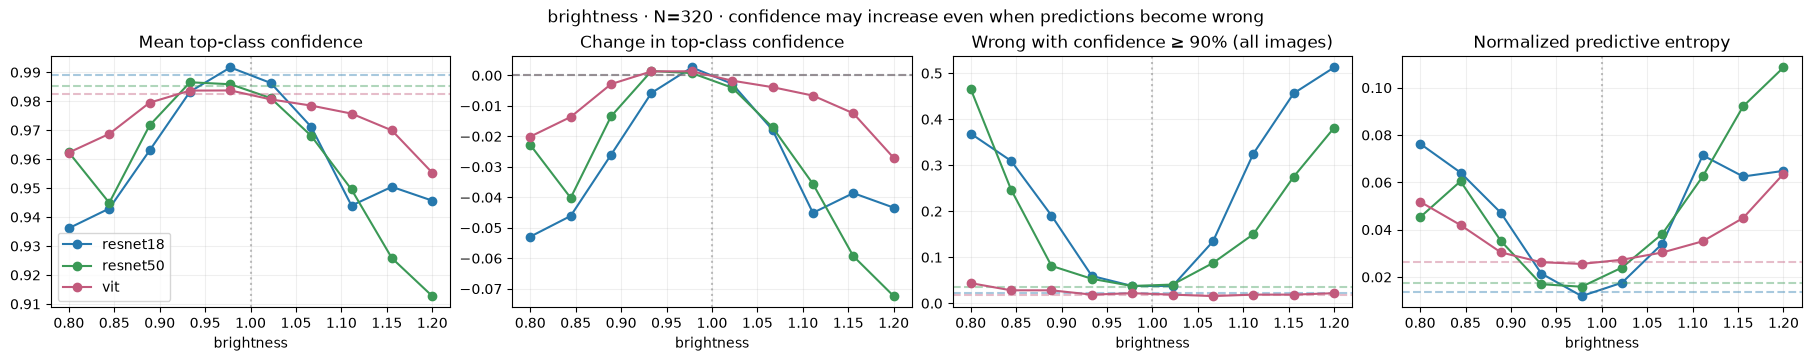

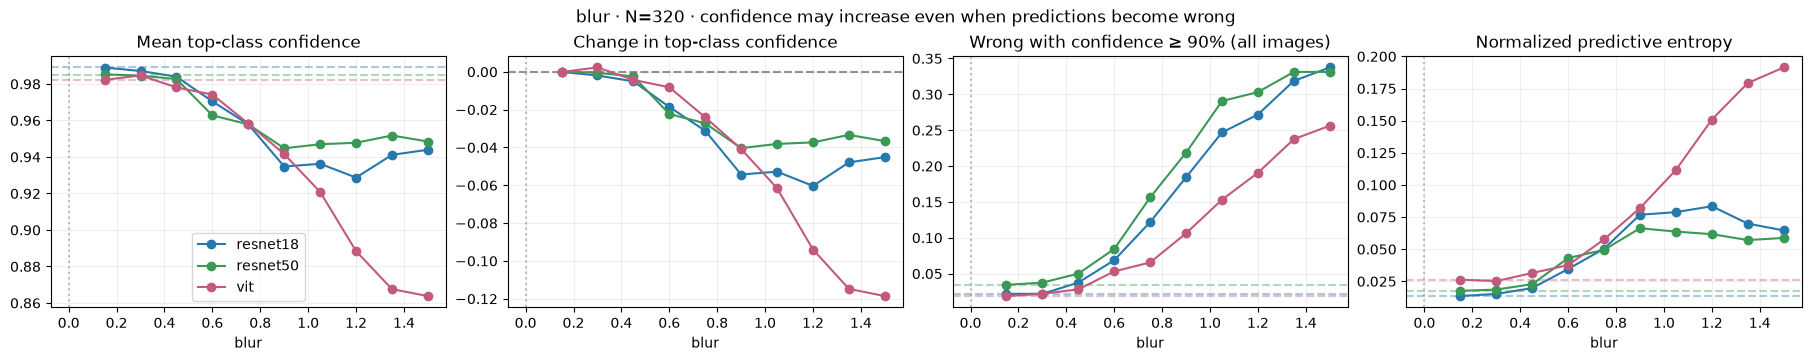

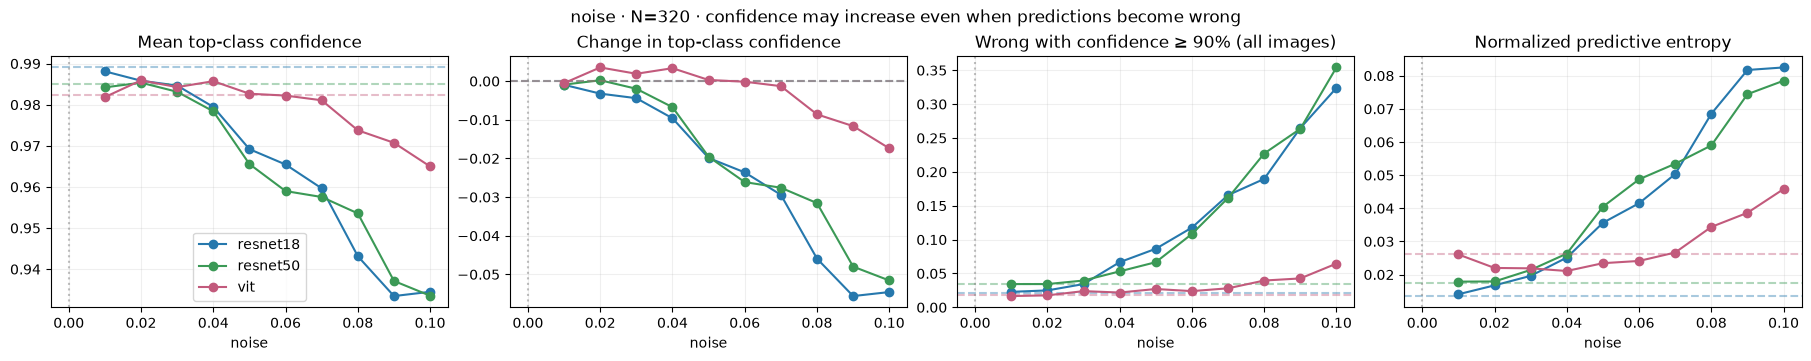

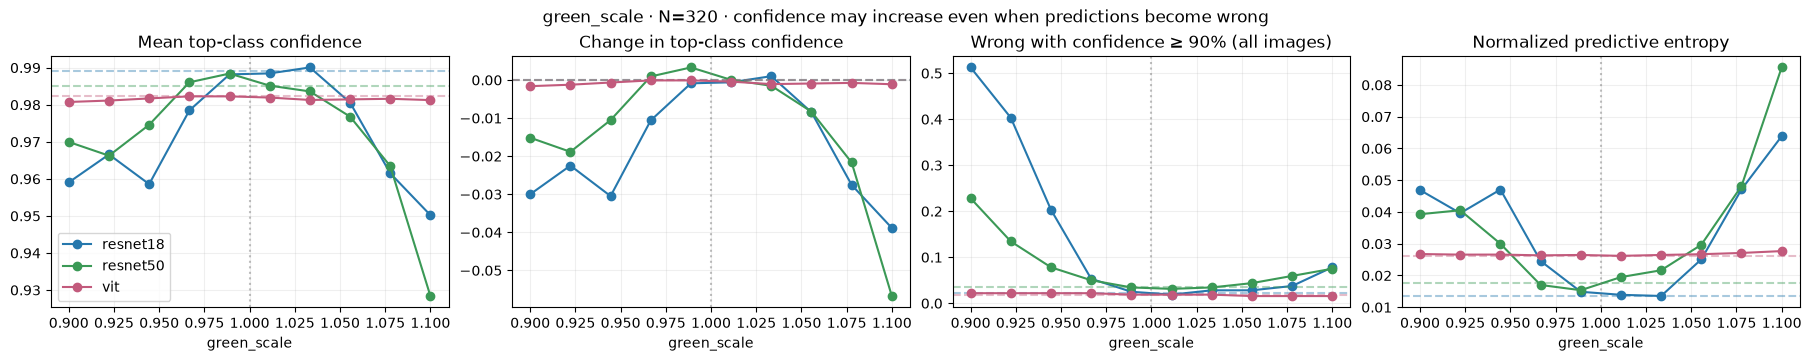

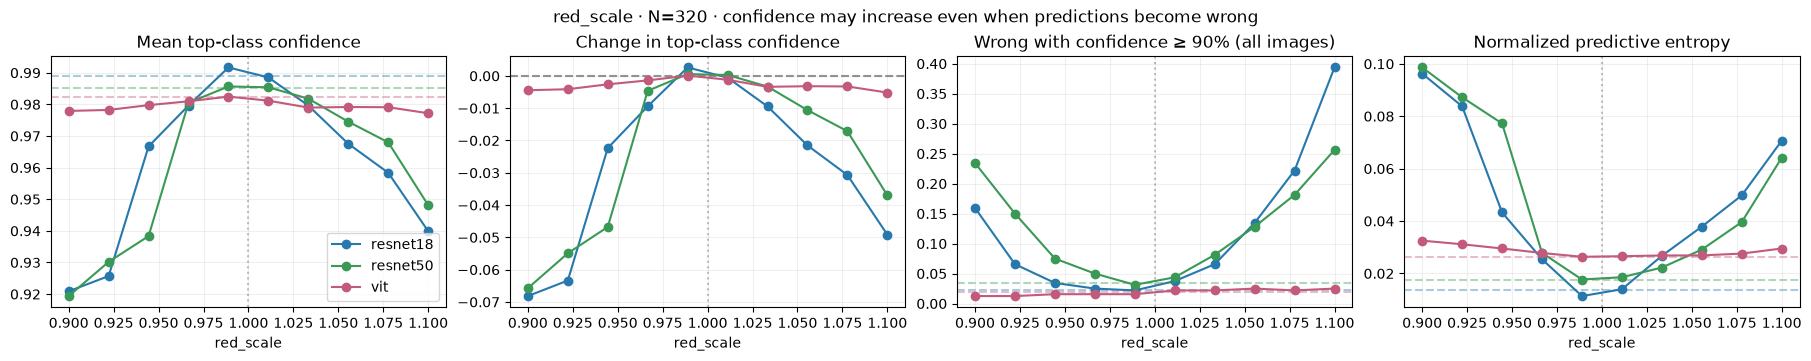

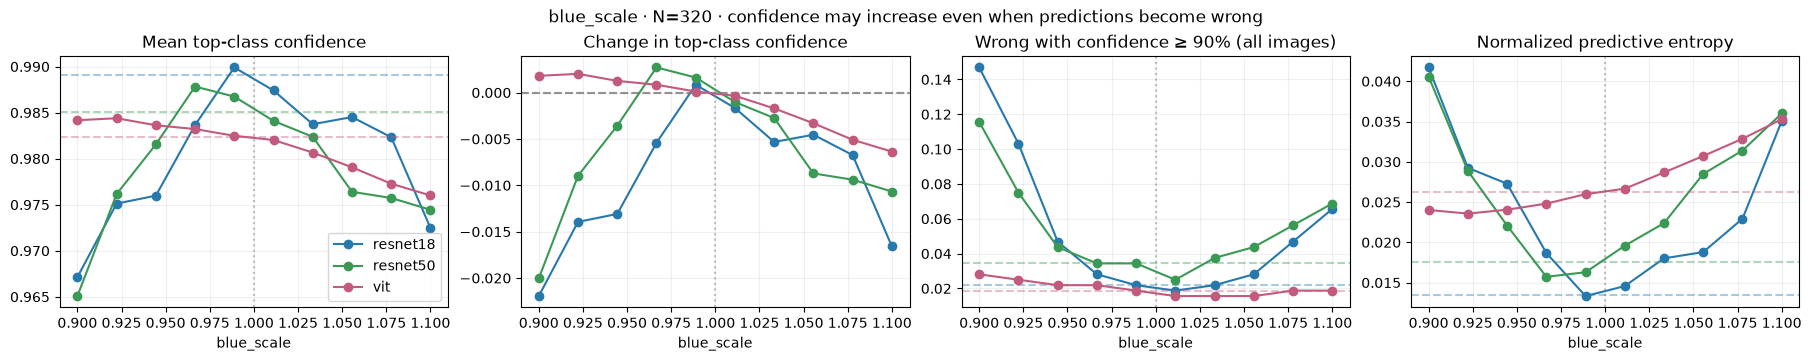

In [6]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
confidence_changes = {}
for kind, p in transformed.items():
    conf = p.max(-1)
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    metrics = {
        'Mean top-class confidence': conf.mean(axis=2),
        'Change in top-class confidence': (conf - base_confidence[:, None, None, :]).mean(axis=2),
        f'Wrong with confidence ≥ {threshold:.0%} (all images)': high_wrong.mean(axis=2),
        'Normalized predictive entropy': entropy(p).mean(axis=2),
    }
    confidence_changes[kind] = metrics
    references = [base_confidence.mean(-1), np.zeros(len(model_names)), base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for ax, (title, values), original in zip(axes, metrics.items(), references):
        for m, name in enumerate(model_names):
            line, = ax.plot(levels[kind], values[m].mean(-1), 'o-', label=name)
            ax.axhline(original[m], color=line.get_color(), ls='--', alpha=0.4)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · confidence may increase even when predictions become wrong')
    plt.show()

## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [7]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold,
                        logits=np.load(f'predictions/{name}_test.npz')['logits'][ids])
    print(f'{name}: {len(ids)} high-confidence errors → {path}')
    print('Test indices:', ids.tolist())

resnet18: 70 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
Test indices: [3126, 340, 1750, 1967, 3015, 476, 35, 496, 3329, 1762, 2823, 873, 683, 1555, 235, 533, 9, 1187, 1462, 1413, 1741, 2908, 3373, 1629, 2512, 963, 1063, 501, 2311, 984, 965, 2177, 3017, 839, 1618, 1220, 209, 2231, 832, 1125, 1399, 1902, 906, 637, 576, 952, 1845, 362, 1182, 831, 1943, 320, 2750, 1130, 2434, 2384, 441, 2649, 1478, 552, 1516, 2706, 642, 1862, 370, 2036, 2830, 1796, 65, 3058]
resnet50: 79 high-confidence errors → predictions\high_confidence_wrong_resnet50.npz
Test indices: [1750, 3126, 3329, 2434, 340, 849, 2908, 476, 873, 3015, 1629, 2935, 496, 2649, 1765, 2776, 839, 1555, 2823, 1846, 379, 1967, 809, 35, 333, 1413, 593, 1130, 2311, 290, 1899, 3373, 1018, 2914, 1249, 2231, 1063, 652, 235, 69, 942, 1660, 944, 8, 683, 2721, 3035, 1762, 2750, 1213, 3025, 102, 831, 952, 1748, 2384, 109, 3212, 396, 1843, 84, 1914, 1546, 642, 1462, 2728, 1680, 963, 1125, 432, 1819, 906, 1371, 2349, 53

## Highest-confidence errors — first eight per model; class IDs follow data/metadata.json; all selected images are saved

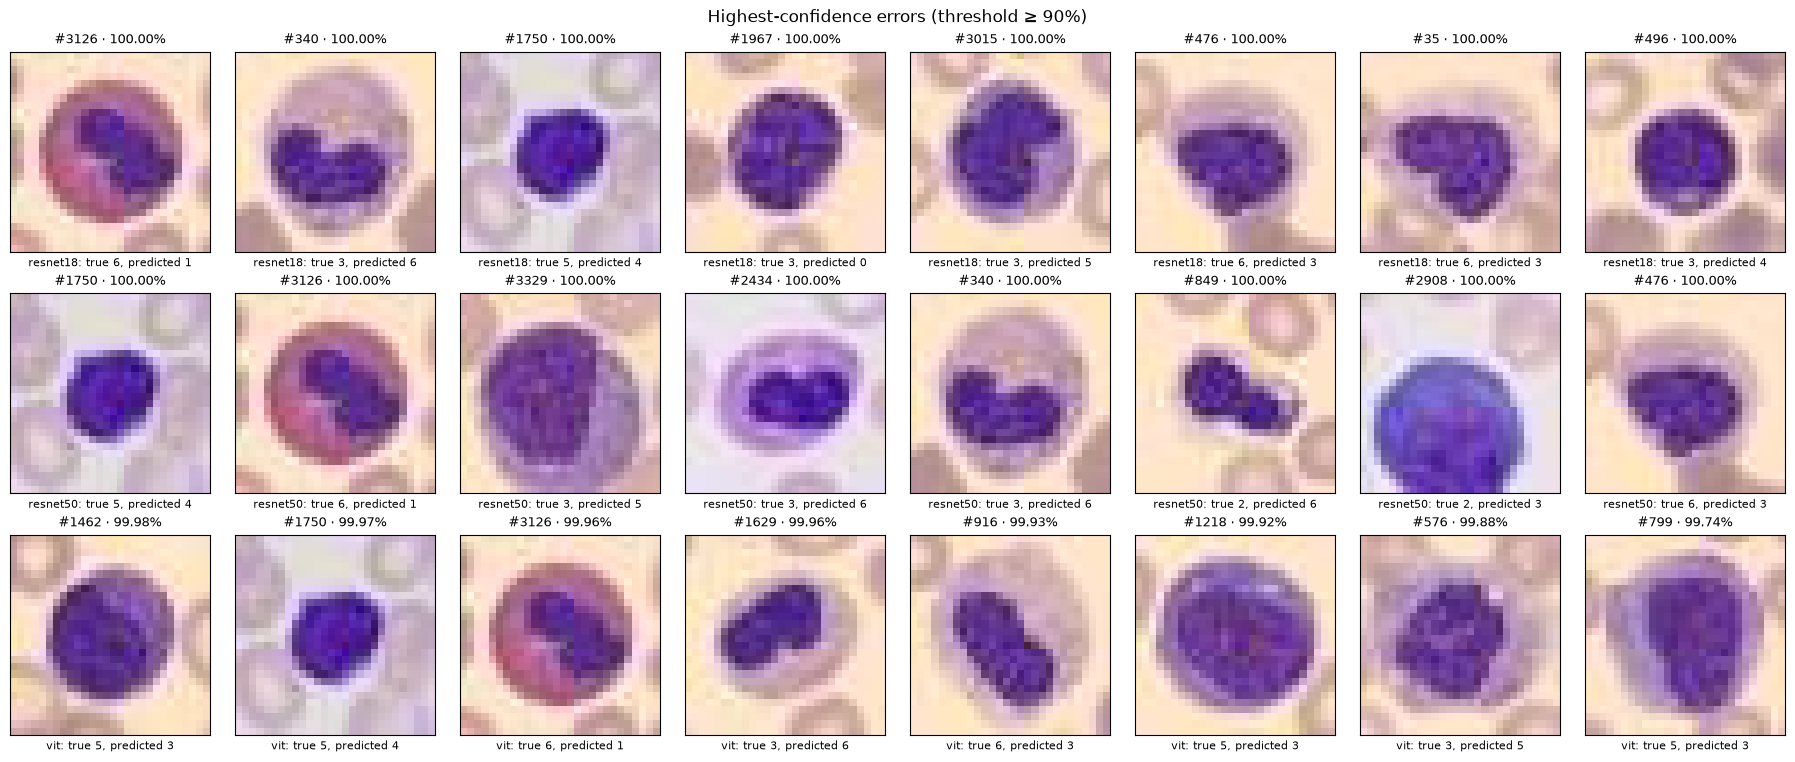

In [8]:
fig, axes = plt.subplots(len(model_names), 8, figsize=(18, 2.5 * len(model_names)), layout='constrained')
for m, name in enumerate(model_names):
    ids = high_confidence_wrong[name][:8]
    for ax in axes[m]:
        ax.axis('off')
    for ax, i in zip(axes[m], ids):
        ax.imshow(images[i])
        ax.set_title(f'#{i} · {confidence[m, i]:.2%}', fontsize=9)
        ax.set_xlabel(f'{name}: true {labels[i]}, predicted {predicted[m, i]}', fontsize=8)
        ax.axis('on')
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle(f'Highest-confidence errors (threshold ≥ {threshold:.0%})')
plt.show()

## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


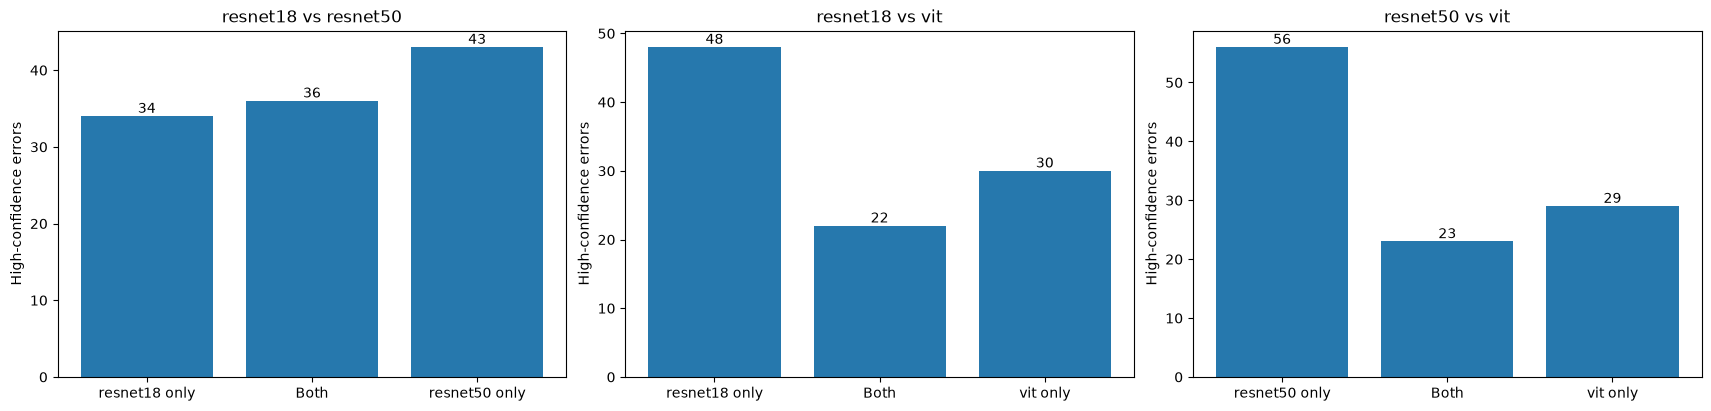

In [9]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

resnet18: immature granulocytes → monocyte: 13/70 (18.6%)
resnet18: immature granulocytes → neutrophil: 11/70 (15.7%)
resnet18: neutrophil → immature granulocytes: 9/70 (12.9%)
resnet18: immature granulocytes → lymphocyte: 6/70 (8.6%)
resnet18: monocyte → immature granulocytes: 5/70 (7.1%)
resnet50: monocyte → immature granulocytes: 12/79 (15.2%)
resnet50: neutrophil → immature granulocytes: 11/79 (13.9%)
resnet50: immature granulocytes → monocyte: 10/79 (12.7%)
resnet50: immature granulocytes → neutrophil: 10/79 (12.7%)
resnet50: basophil → immature granulocytes: 5/79 (6.3%)
vit: monocyte → immature granulocytes: 9/52 (17.3%)
vit: immature granulocytes → monocyte: 8/52 (15.4%)
vit: neutrophil → immature granulocytes: 8/52 (15.4%)
vit: basophil → immature granulocytes: 7/52 (13.5%)
vit: immature granulocytes → neutrophil: 6/52 (11.5%)


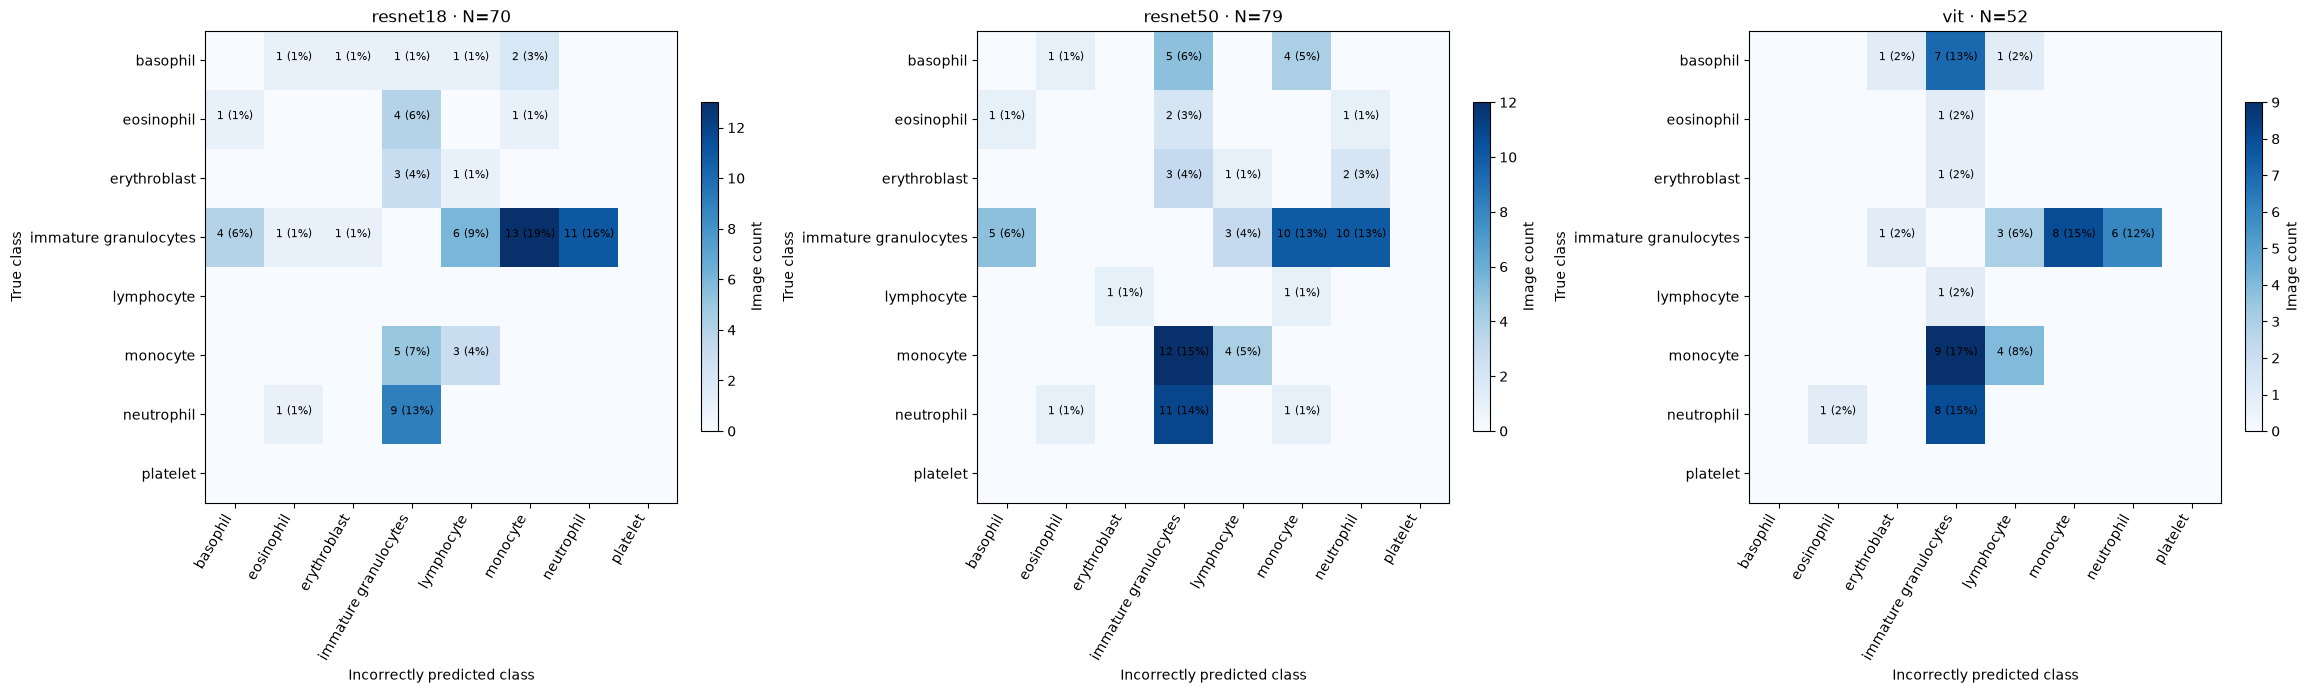

In [10]:
confusions, example_ids = [], []
fig, axes = plt.subplots(1, len(model_names), figsize=(23, 7), layout='constrained')
for m, (ax, ids) in enumerate(zip(axes, error_ids)):
    matrix = np.zeros((8, 8), dtype=int)
    np.add.at(matrix, (labels[ids], predicted[m, ids]), 1)
    confusions.append(matrix)
    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(matrix.max(), 1))
    ax.set(title=f'{model_names[m]} · N={len(ids)}', xlabel='Incorrectly predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c, d in zip(*np.nonzero(matrix)):
        ax.text(d, c, f'{matrix[c, d]} ({matrix[c, d] / len(ids):.0%})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Image count')
    pairs = np.dstack(np.unravel_index(np.argsort(-matrix.ravel(), kind='stable'), matrix.shape))[0]
    pairs = [(c, d) for c, d in pairs if matrix[c, d] > 0]
    for c, d in pairs[:5]:
        print(f'{model_names[m]}: {class_names[c]} → {class_names[d]}: {matrix[c, d]}/{len(ids)} ({matrix[c, d] / len(ids):.1%})')
    example_ids.append(np.array([ids[np.flatnonzero((labels[ids] == c) & (predicted[m, ids] == d))[0]] for c, d in pairs[:3]], dtype=int))
plt.show()

## Simple RGB features — boundary gradient energy is only a proxy for edge content, not cell location or segmentation

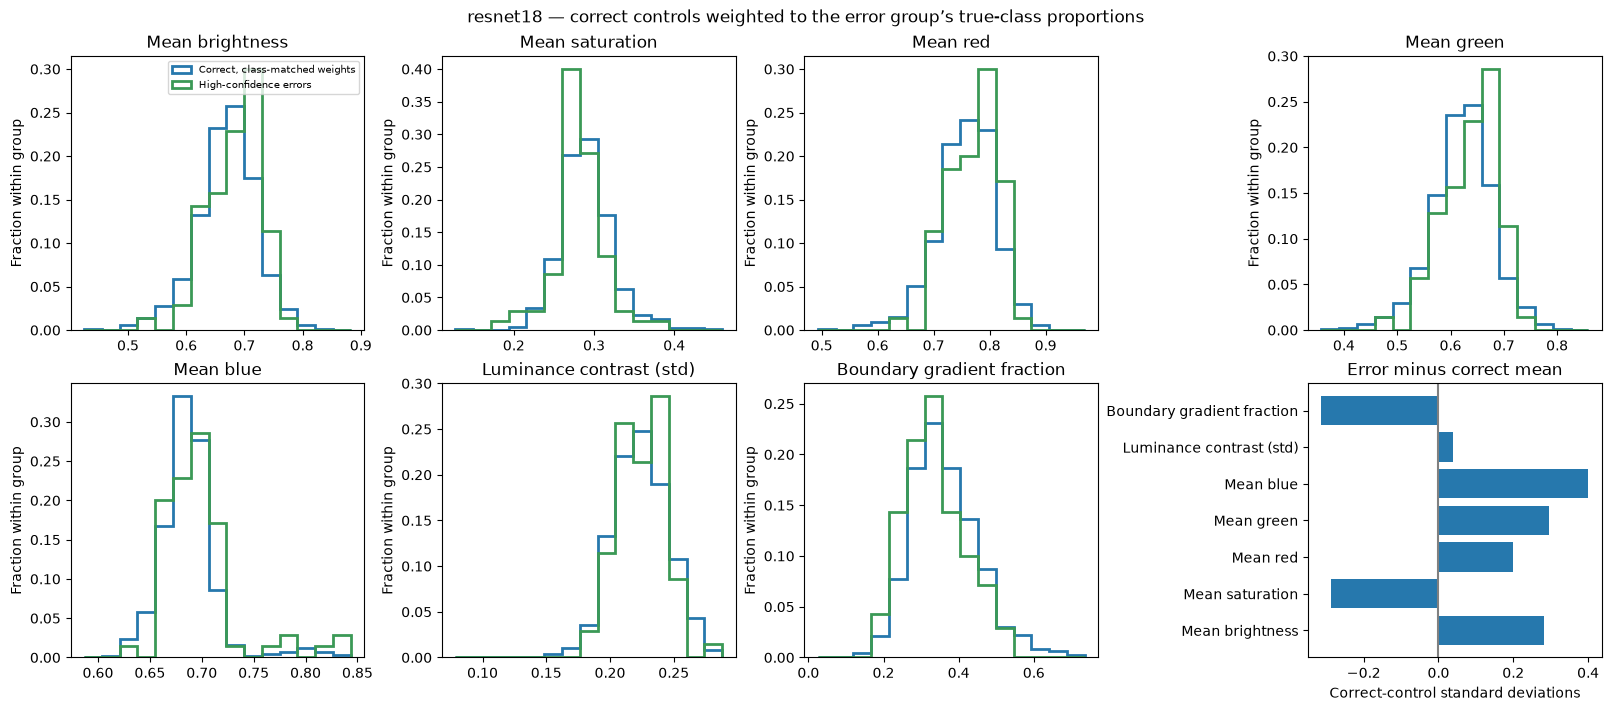

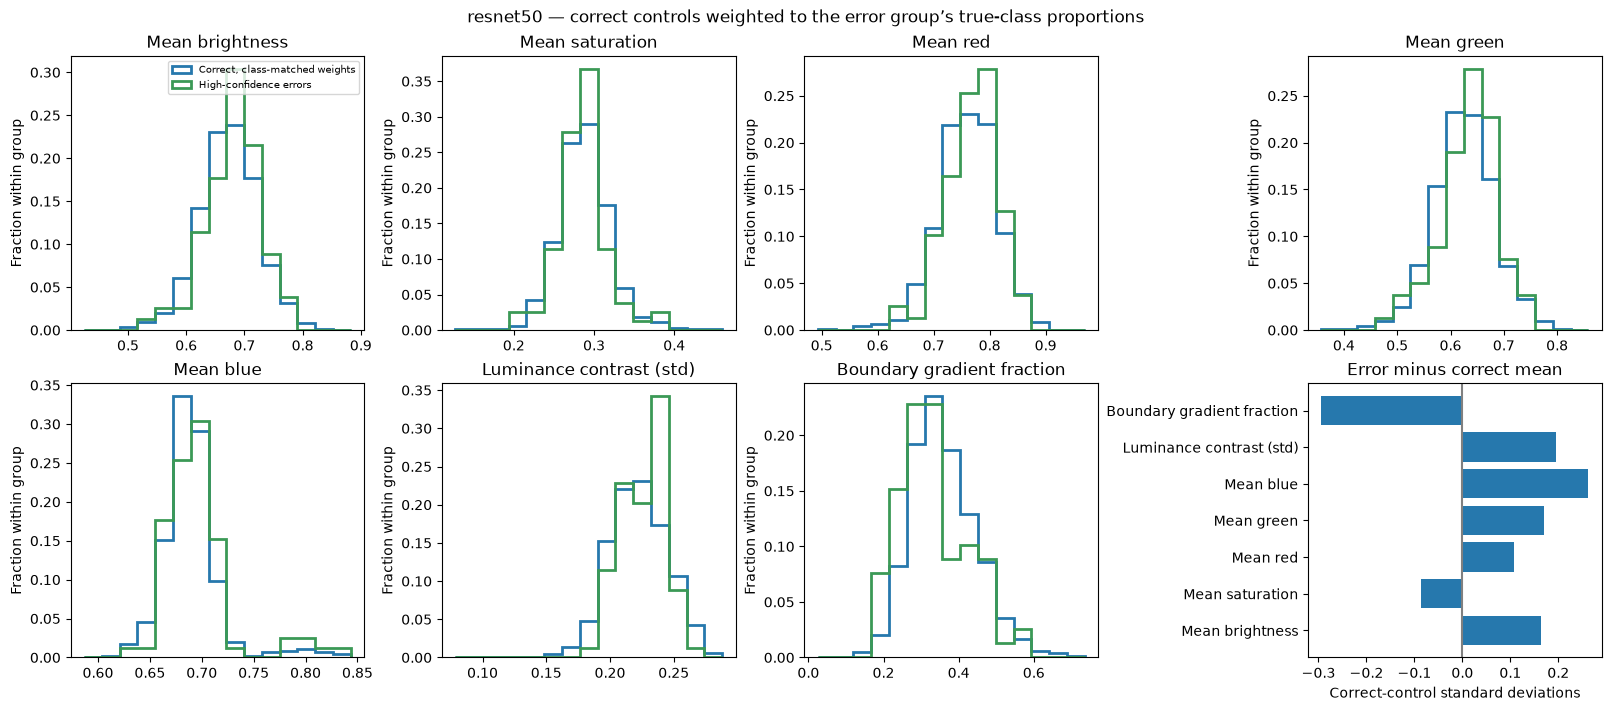

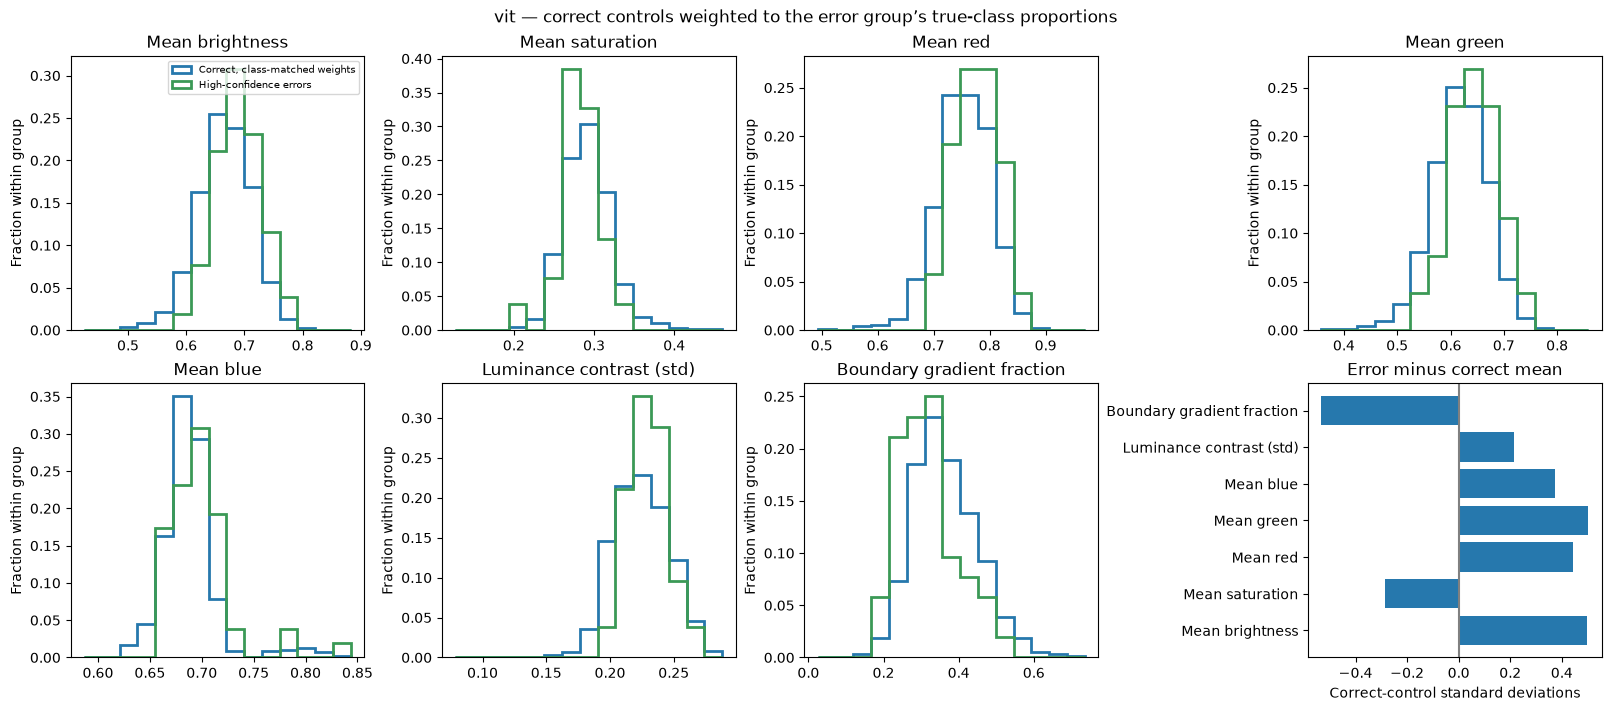

In [11]:
rgb = images.astype(float) / 255
luminance = rgb @ np.array([0.299, 0.587, 0.114])
maximum, minimum = rgb.max(-1), rgb.min(-1)
saturation = np.divide(maximum - minimum, maximum, out=np.zeros_like(maximum), where=maximum > 0)
gy, gx = np.gradient(luminance, axis=(1, 2))
energy = np.hypot(gx, gy)
border = np.ones((28, 28), dtype=bool)
border[4:-4, 4:-4] = False
boundary_energy = energy[:, border].sum(-1) / np.maximum(energy.sum((1, 2)), 1e-12)
features = np.column_stack((luminance.mean((1, 2)), saturation.mean((1, 2)),
                            rgb.mean((1, 2)), luminance.std((1, 2)), boundary_energy))
feature_names = ['Mean brightness', 'Mean saturation', 'Mean red', 'Mean green', 'Mean blue',
                 'Luminance contrast (std)', 'Boundary gradient fraction']
control_weights, feature_effects = [], []
for m, ids in enumerate(error_ids):
    weights = np.zeros(len(labels))
    for c in range(8):
        mask = correct[m] & (labels == c)
        if mask.any() and len(ids):
            weights[mask] = (labels[ids] == c).mean() / mask.sum()
    control_weights.append(weights)
    if not len(ids):
        feature_effects.append(np.full(len(feature_names), np.nan))
        continue
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    effects = (features[ids].mean(0) - mean) / np.maximum(std, 1e-12)
    feature_effects.append(effects)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout='constrained')
    for j, ax in enumerate(axes.flat[:7]):
        edges = np.linspace(features[:, j].min(), features[:, j].max() + 1e-12, 16)
        ax.hist(features[:, j], bins=edges, weights=weights, histtype='step', linewidth=2, label='Correct, class-matched weights')
        ax.hist(features[ids, j], bins=edges, weights=np.full(len(ids), 1 / len(ids)),
                histtype='step', linewidth=2, label='High-confidence errors')
        ax.set(title=feature_names[j], ylabel='Fraction within group')
    axes[0, 0].legend(fontsize=7)
    axes[1, 3].barh(feature_names, effects)
    axes[1, 3].axvline(0, color='gray')
    axes[1, 3].set(title='Error minus correct mean', xlabel='Correct-control standard deviations')
    fig.suptitle(f'{model_names[m]} — correct controls weighted to the error group’s true-class proportions')
    plt.show()

## Similar correctly classified images — nearest raw-RGB RMSE match in the true and predicted classes; class sizes and image alignment affect similarity

resnet18: predicted-class neighbor closer in 62.9% of high-confidence errors


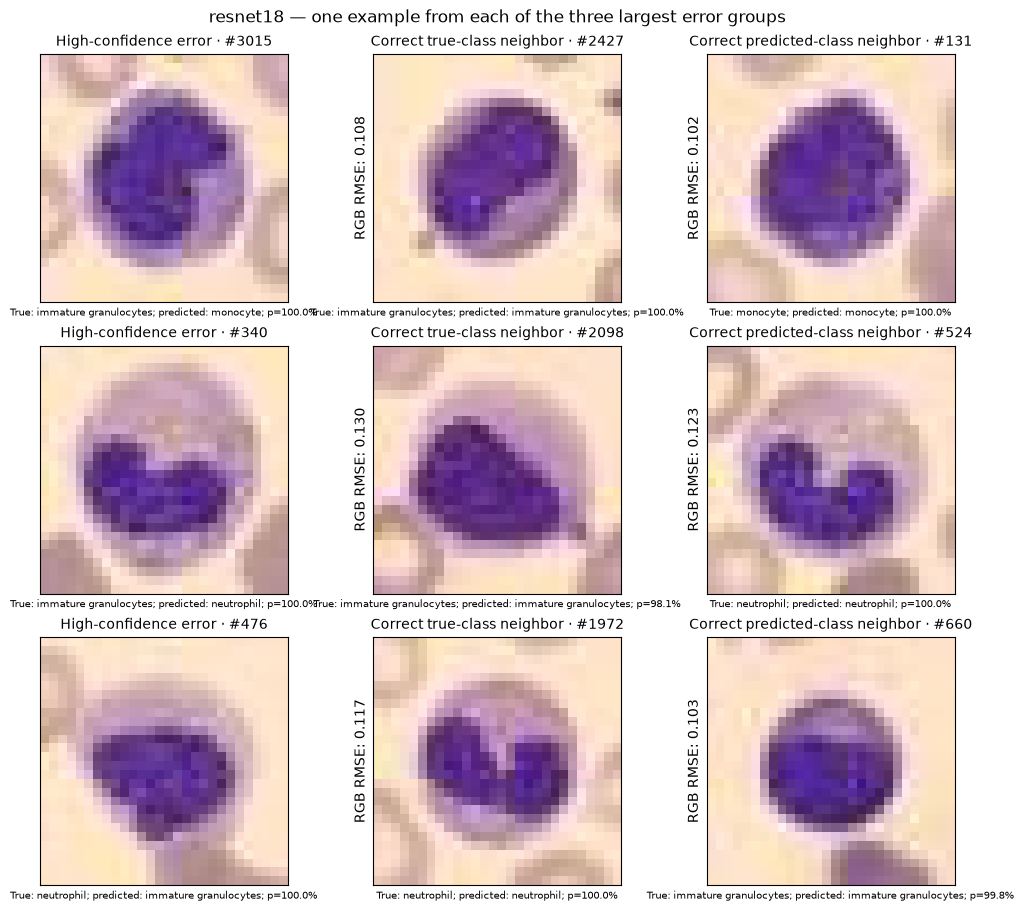

resnet50: predicted-class neighbor closer in 59.5% of high-confidence errors


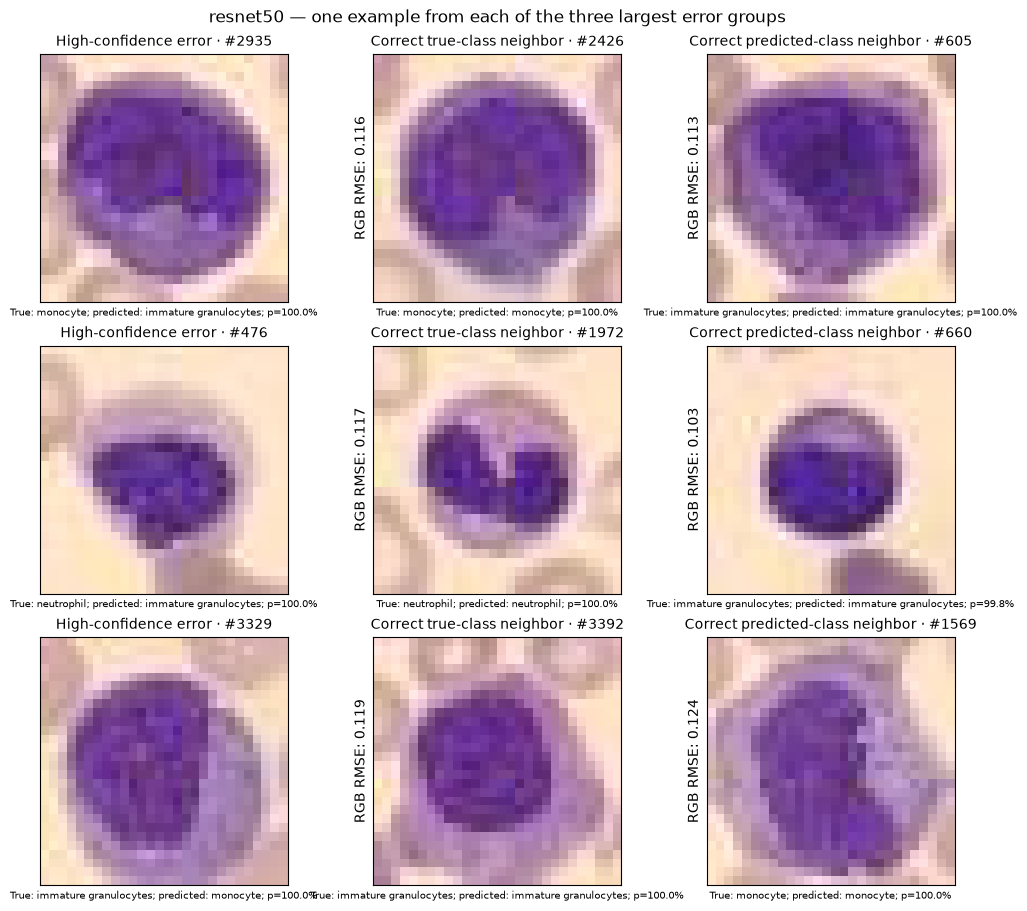

vit: predicted-class neighbor closer in 61.5% of high-confidence errors


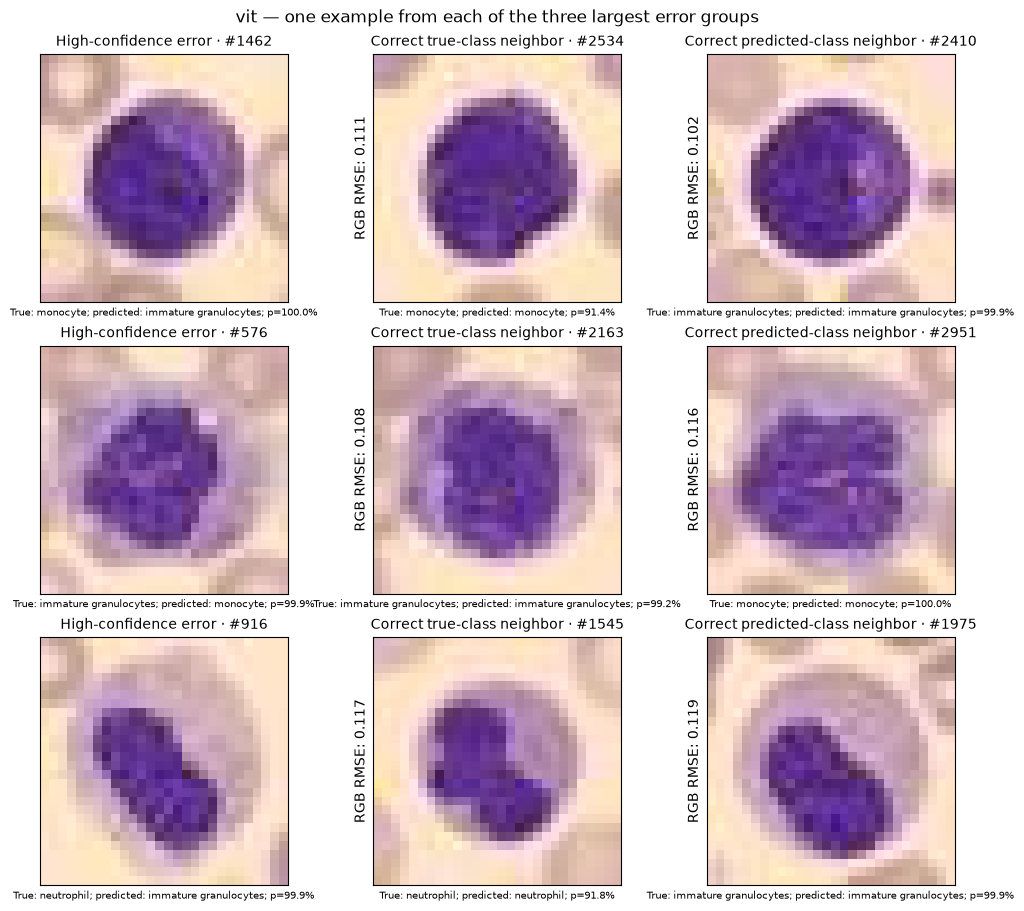

In [12]:
flat = rgb.reshape(len(images), -1).astype(np.float32)
squared = np.square(flat).sum(-1)
neighbor_ids, neighbor_rmse = [], []
for m, ids in enumerate(error_ids):
    distances = np.maximum(squared[:, None] + squared[ids][None, :] - 2 * flat @ flat[ids].T, 0) / flat.shape[1]
    matches, rmses = [], []
    for target in [labels[ids], predicted[m, ids]]:
        allowed = correct[m, :, None] & (labels[:, None] == target[None, :])
        assert allowed.any(axis=0).all(), 'No correct comparison image in a requested class'
        nearest = np.where(allowed, distances, np.inf).argmin(axis=0)
        matches.append(nearest)
        rmses.append(np.sqrt(distances[nearest, np.arange(len(ids))]))
    neighbor_ids.append(np.stack(matches))
    neighbor_rmse.append(np.stack(rmses))
    if not len(example_ids[m]):
        continue
    print(f'{model_names[m]}: predicted-class neighbor closer in {(rmses[1] < rmses[0]).mean():.1%} of high-confidence errors')
    fig, axes = plt.subplots(len(example_ids[m]), 3, figsize=(10, 3 * len(example_ids[m])), squeeze=False, layout='constrained')
    for row, i in enumerate(example_ids[m]):
        pos = np.flatnonzero(ids == i)[0]
        comparison = [i, matches[0][pos], matches[1][pos]]
        titles = ['High-confidence error', 'Correct true-class neighbor', 'Correct predicted-class neighbor']
        for col, (j, title) in enumerate(zip(comparison, titles)):
            ax = axes[row, col]
            ax.imshow(images[j])
            ax.set_title(f'{title} · #{j}', fontsize=10)
            ax.set_xlabel(f'True: {class_names[labels[j]]}; predicted: {class_names[predicted[m, j]]}; p={confidence[m, j]:.1%}', fontsize=7)
            if col:
                ax.set_ylabel(f'RGB RMSE: {rmses[col - 1][pos]:.3f}')
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle(f'{model_names[m]} — one example from each of the three largest error groups')
    plt.show()

## Load models for interventions — no training; saturation and occlusion act on original 28 × 28 RGB images

In [13]:
import torch
from PIL import Image, ImageEnhance
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 32
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

def intervention_predict(m, batch_images):
    return predict(m, batch_images)[0]

for m, ids in enumerate(error_ids):
    if len(ids):
        np.testing.assert_allclose(intervention_predict(m, images[ids]), probabilities[m, ids], atol=1e-5, rtol=1e-4)


## Saturation intervention — errors versus their nearest correctly classified true-class controls; repeated control images are not independent samples

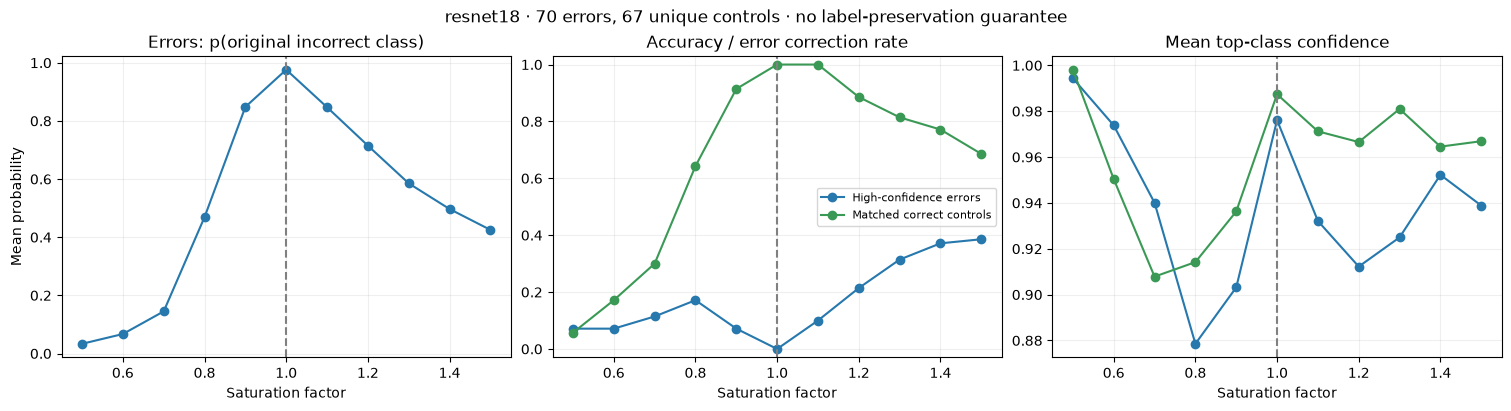

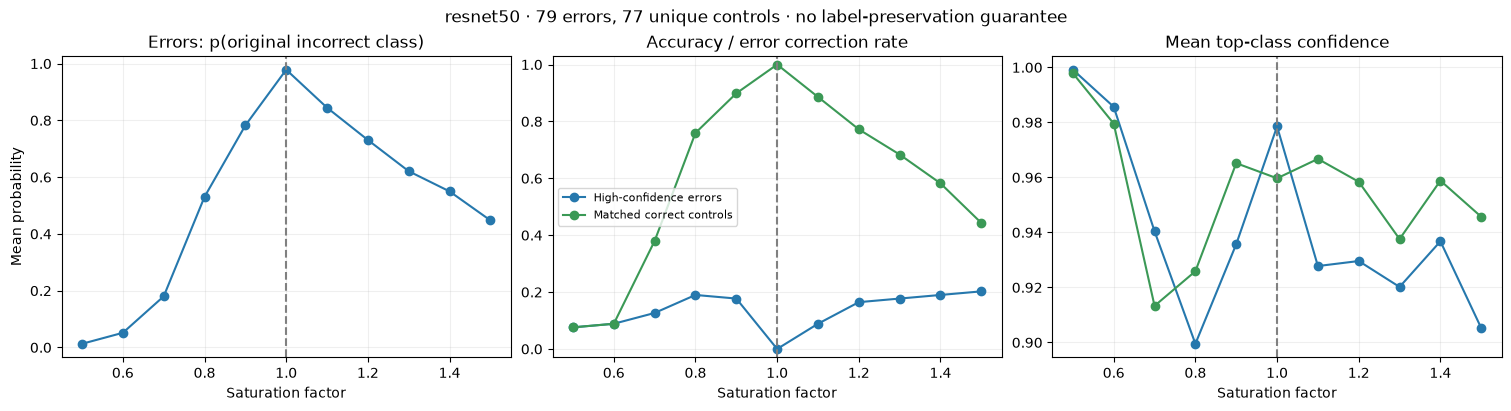

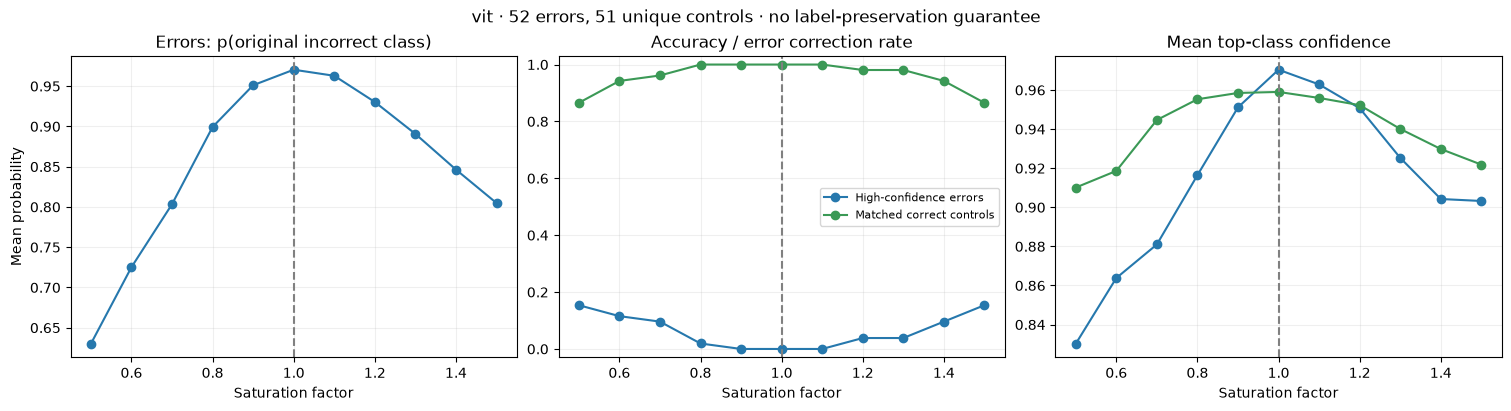

In [14]:
saturation_levels = np.linspace(0.5, 1.5, 11)
saturation_results, saturation_ids = [], []
for m, ids in enumerate(error_ids):
    selected = np.stack((ids, neighbor_ids[m][0]))
    saturation_ids.append(selected)
    if not len(ids):
        saturation_results.append(np.empty((2, 11, 0, 8)))
        continue
    inputs = images[selected.ravel()]
    values = []
    for level in saturation_levels:
        changed = np.stack([np.asarray(ImageEnhance.Color(Image.fromarray(image)).enhance(float(level))) for image in inputs])
        values.append(intervention_predict(m, changed).reshape(2, len(ids), 8))
    p = np.stack(values, axis=1)
    saturation_results.append(p)
    np.testing.assert_allclose(p[:, 5], probabilities[m, selected], atol=1e-5, rtol=1e-4)
    wrong_probability = np.take_along_axis(p[0], predicted[m, ids][None, :, None], axis=-1)[..., 0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
    axes[0].plot(saturation_levels, wrong_probability.mean(-1), 'o-')
    axes[0].set(title='Errors: p(original incorrect class)', ylabel='Mean probability')
    for role, title in enumerate(['High-confidence errors', 'Matched correct controls']):
        accuracy = (p[role].argmax(-1) == labels[selected[role]]).mean(-1)
        axes[1].plot(saturation_levels, accuracy, 'o-', label=title)
        axes[2].plot(saturation_levels, p[role].max(-1).mean(-1), 'o-', label=title)
    axes[1].set(title='Accuracy / error correction rate', ylim=(-0.03, 1.03))
    axes[2].set(title='Mean top-class confidence')
    for ax in axes:
        ax.axvline(1, color='gray', ls='--')
        ax.set_xlabel('Saturation factor')
        ax.grid(alpha=0.2)
    axes[1].legend(fontsize=8)
    fig.suptitle(f'{model_names[m]} · {len(ids)} errors, {len(np.unique(selected[1]))} unique controls · no label-preservation guarantee')
    plt.show()

## Occlusion — cover every 4 × 4 patch with gray RGB (128, 128, 128); positive drop means reduced probability of the original wrong class

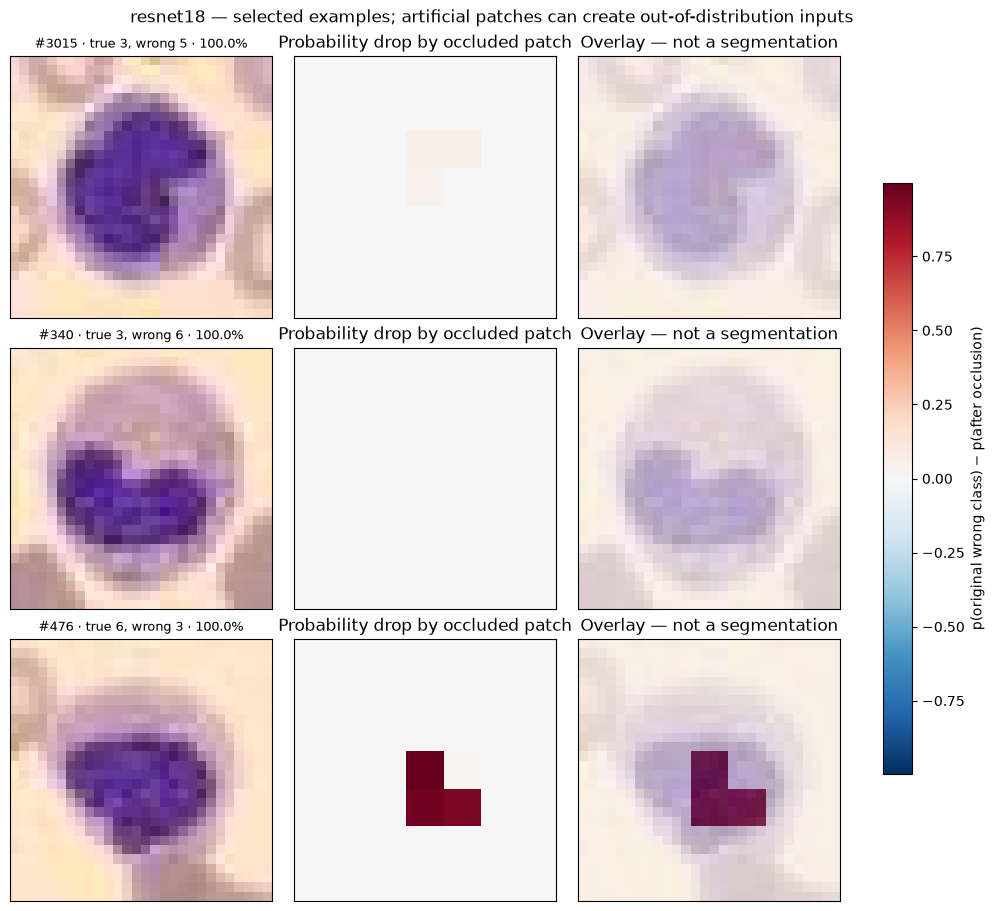

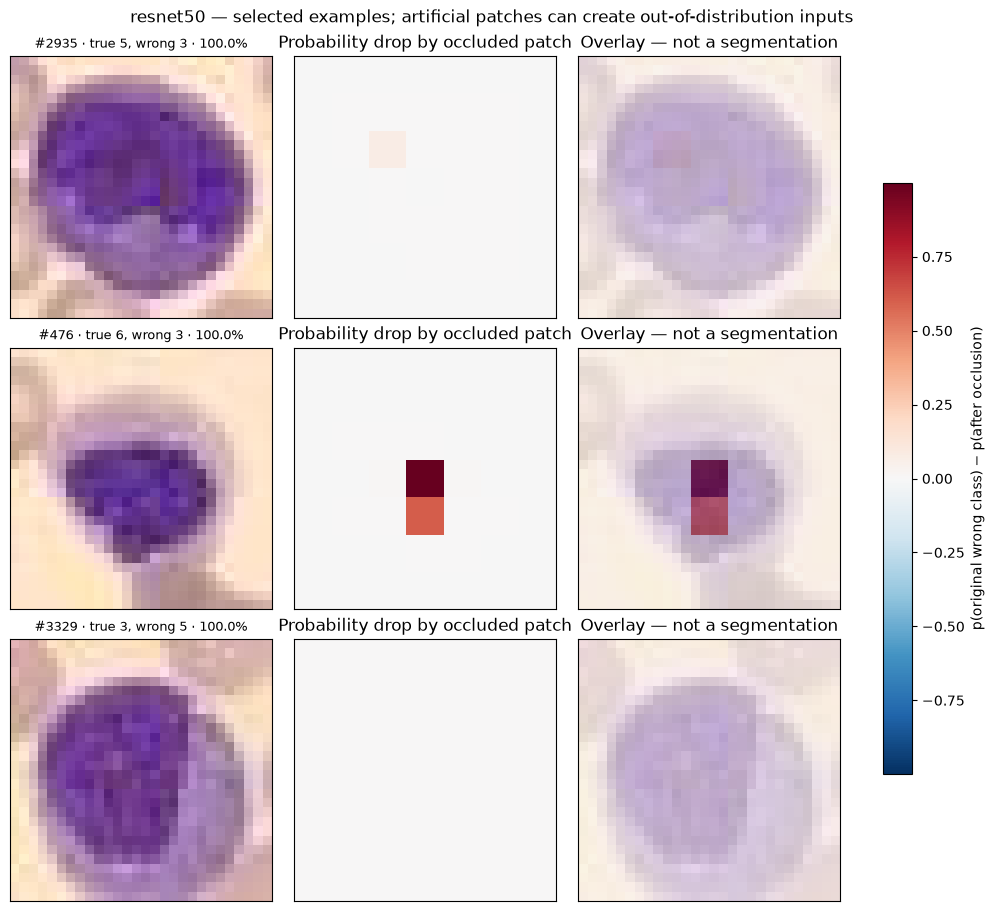

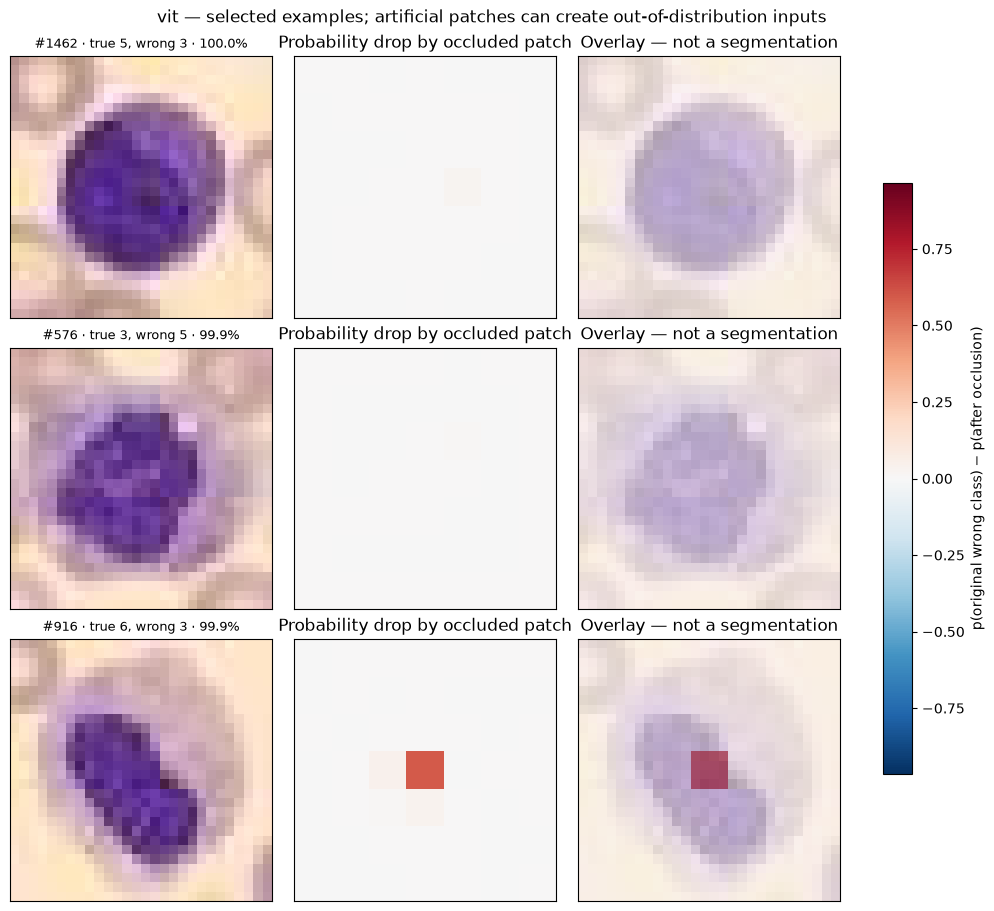

In [15]:
patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
occlusion_results, occlusion_drop = [], []
for m, ids in enumerate(error_ids):
    if not len(ids):
        occlusion_results.append(np.empty((49, 0, 8)))
        occlusion_drop.append(np.empty((0, 7, 7)))
        continue
    changed = np.repeat(images[ids][None], len(positions), axis=0)
    for j, (y, x) in enumerate(positions):
        changed[j, :, y:y + patch_size, x:x + patch_size] = 128
    p = intervention_predict(m, changed.reshape(-1, 28, 28, 3)).reshape(len(positions), len(ids), 8)
    occlusion_results.append(p)
    target = np.take_along_axis(p, predicted[m, ids][None, :, None], axis=-1)[..., 0]
    maps = (confidence[m, ids][None] - target).T.reshape(len(ids), 7, 7)
    occlusion_drop.append(maps)
    fig, axes = plt.subplots(len(example_ids[m]), 3, figsize=(10, 3 * len(example_ids[m])), squeeze=False, layout='constrained')
    scale = max(np.abs(maps).max(), 0.01)
    for row, i in enumerate(example_ids[m]):
        pos = np.flatnonzero(ids == i)[0]
        heat = np.repeat(np.repeat(maps[pos], patch_size, axis=0), patch_size, axis=1)
        axes[row, 0].imshow(images[i])
        axes[row, 0].set_title(f'#{i} · true {labels[i]}, wrong {predicted[m, i]} · {confidence[m, i]:.1%}', fontsize=9)
        im = axes[row, 1].imshow(maps[pos], cmap='RdBu_r', vmin=-scale, vmax=scale)
        axes[row, 1].set_title('Probability drop by occluded patch')
        axes[row, 2].imshow(images[i])
        axes[row, 2].imshow(heat, cmap='RdBu_r', vmin=-scale, vmax=scale, alpha=0.6)
        axes[row, 2].set_title('Overlay — not a segmentation')
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.7, label='p(original wrong class) − p(after occlusion)')
    fig.suptitle(f'{model_names[m]} — selected examples; artificial patches can create out-of-distribution inputs')
    plt.show()

## Occlusion aggregated by true class and model — all high-confidence errors; mean signed drop, absolute effect and correction fraction; N = images, not patches; fixed image coordinates are not aligned cell structures

resnet18 · basophil · N=6 · mean absolute effect=0.136 · correction fraction across patches=1.7%
resnet18 · eosinophil · N=6 · mean absolute effect=0.092 · correction fraction across patches=6.8%
resnet18 · erythroblast · N=4 · mean absolute effect=0.075 · correction fraction across patches=5.6%
resnet18 · immature granulocytes · N=36 · mean absolute effect=0.123 · correction fraction across patches=9.0%
resnet18 · monocyte · N=8 · mean absolute effect=0.061 · correction fraction across patches=4.1%
resnet18 · neutrophil · N=10 · mean absolute effect=0.072 · correction fraction across patches=6.1%
resnet50 · basophil · N=10 · mean absolute effect=0.075 · correction fraction across patches=0.6%
resnet50 · eosinophil · N=4 · mean absolute effect=0.103 · correction fraction across patches=5.1%
resnet50 · erythroblast · N=6 · mean absolute effect=0.136 · correction fraction across patches=12.6%
resnet50 · immature granulocytes · N=28 · mean absolute effect=0.147 · correction fraction acros

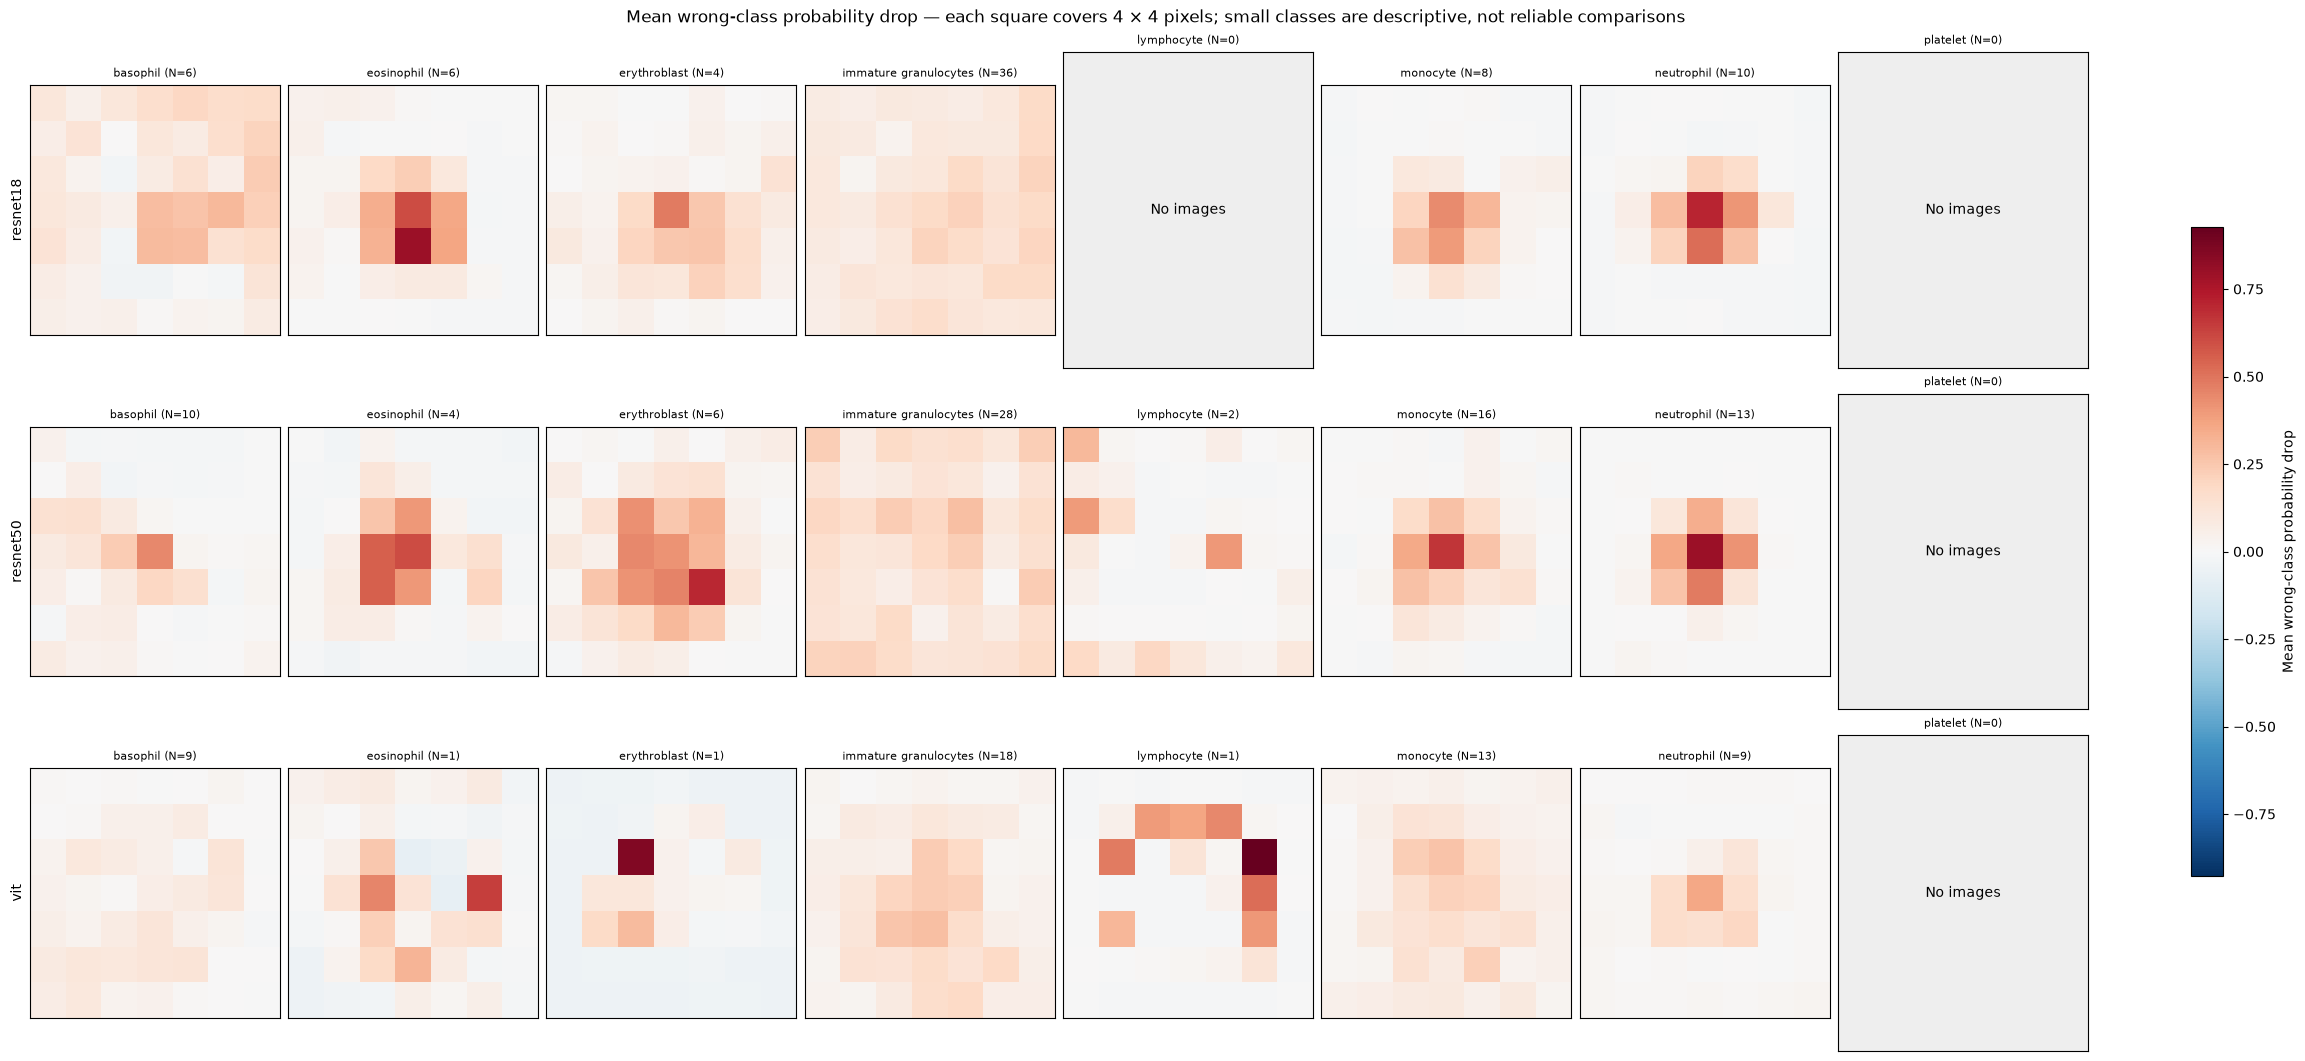

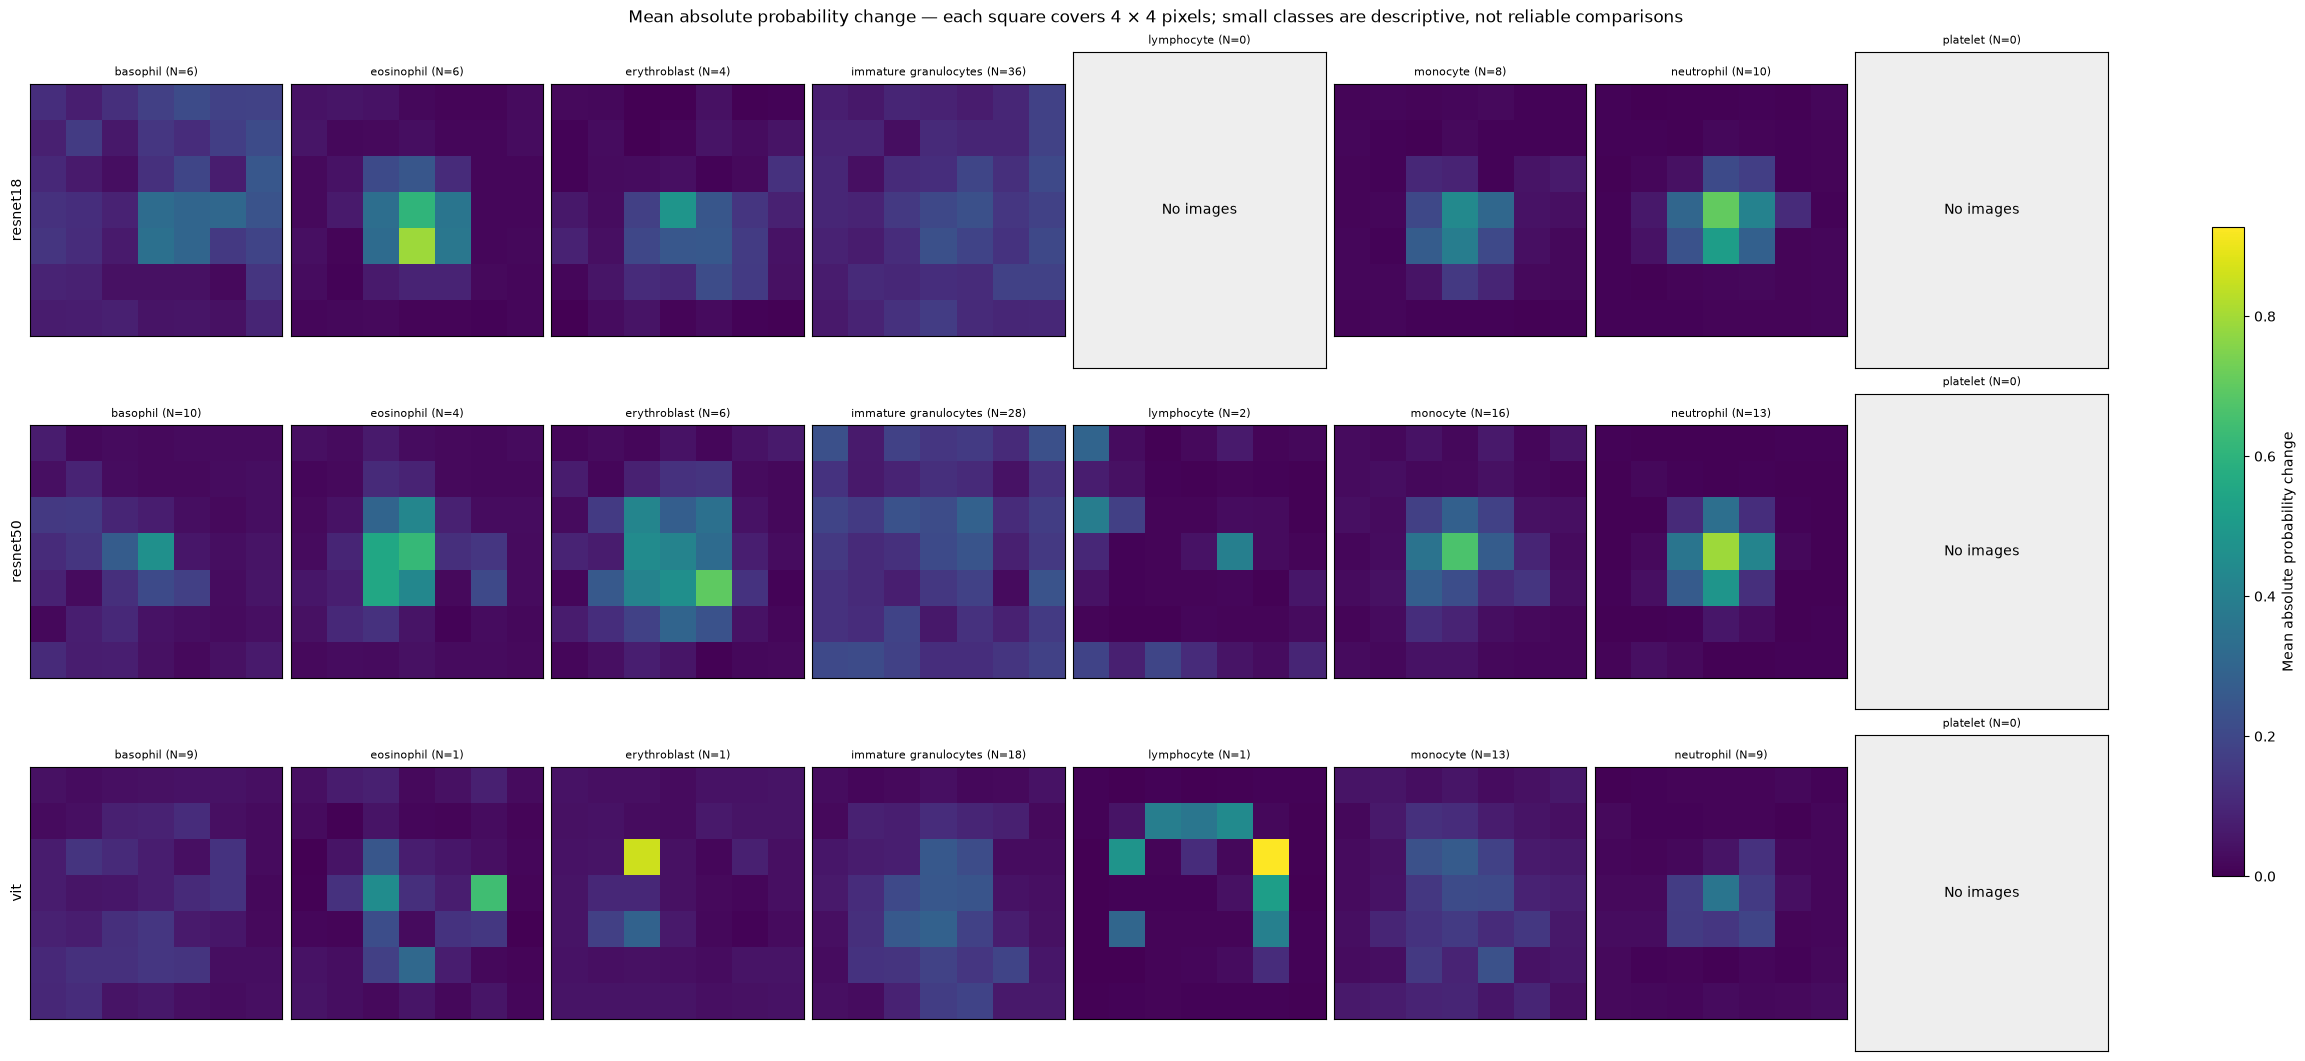

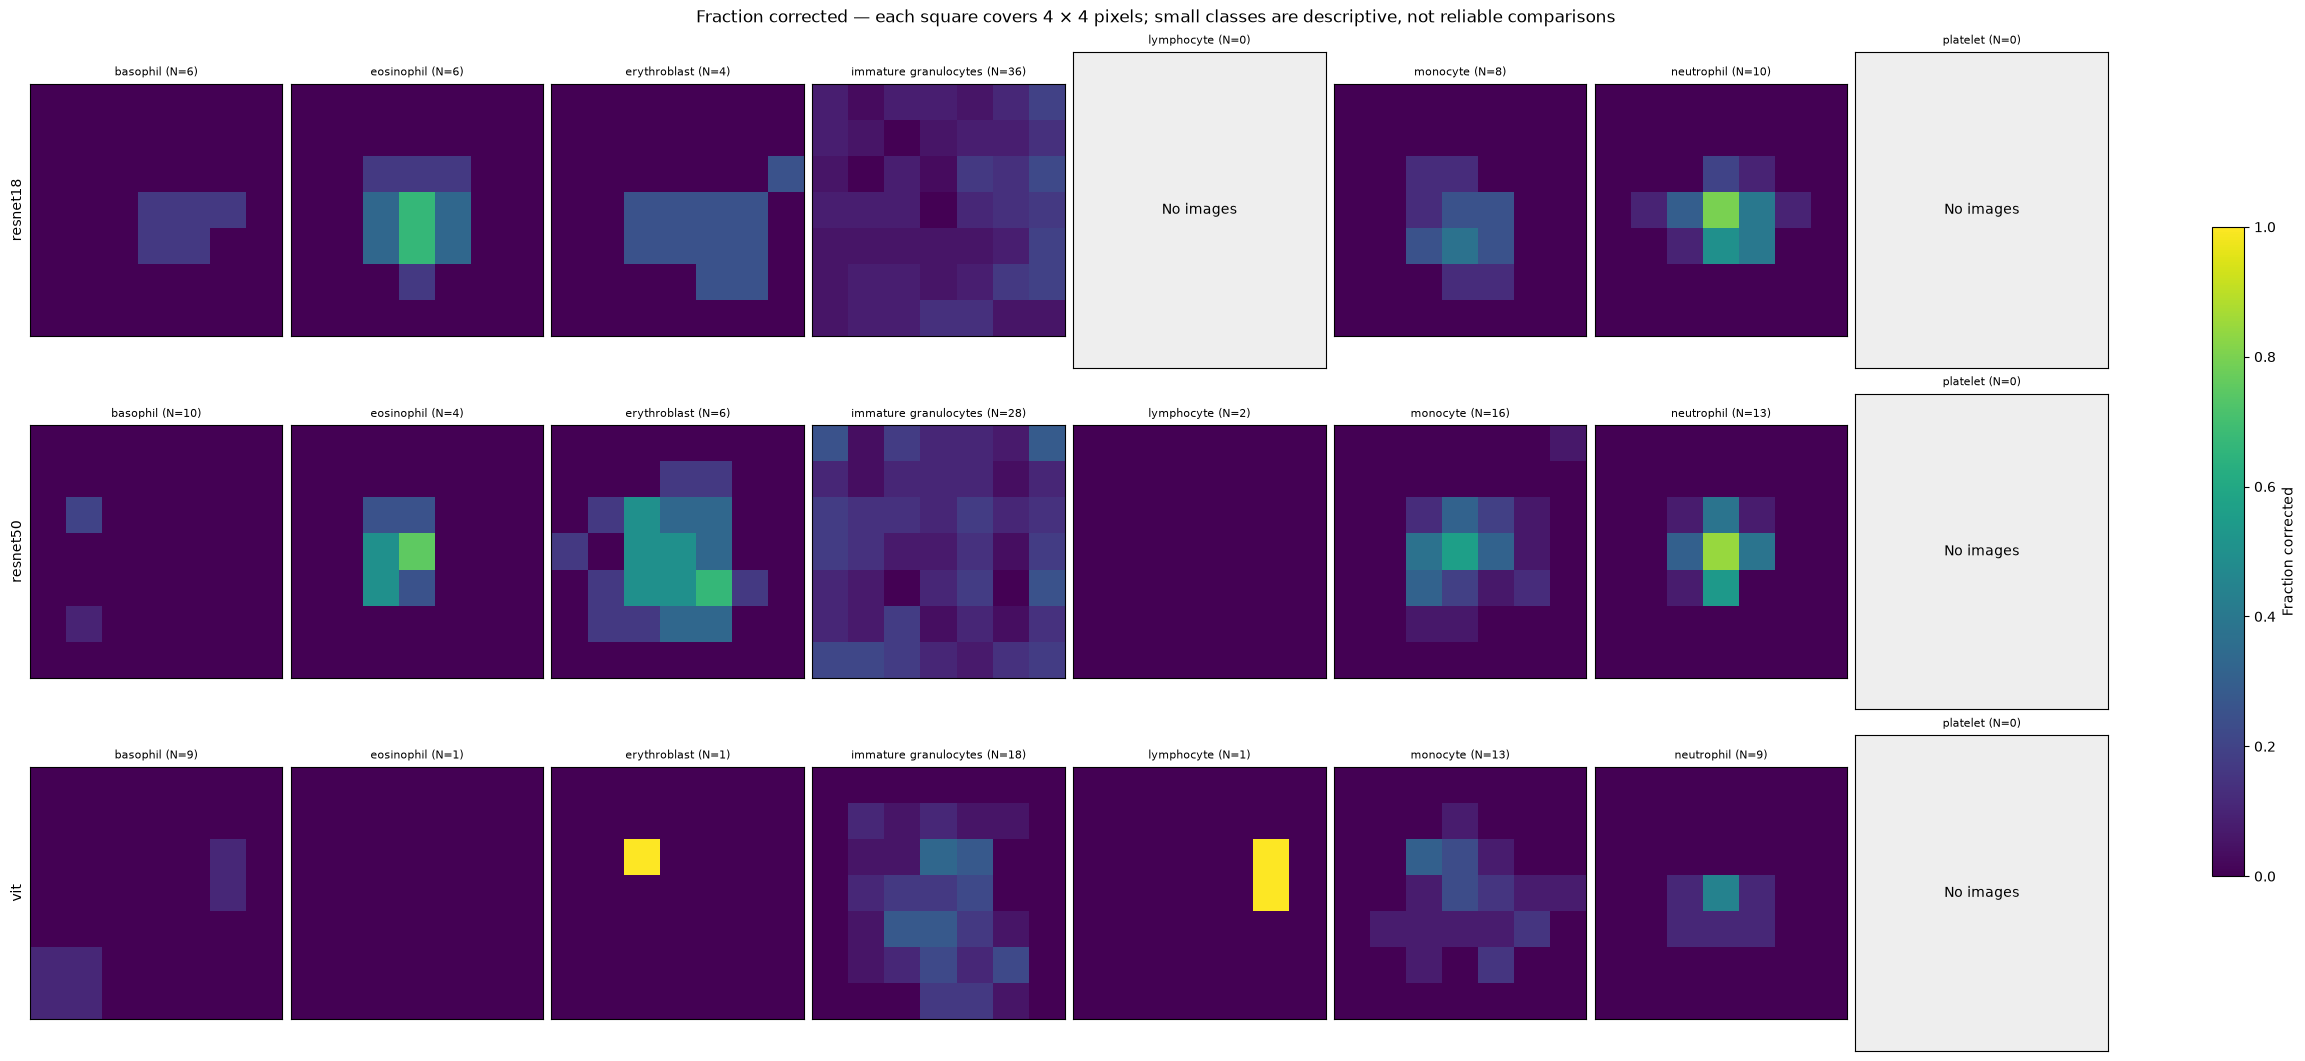

Model cohorts differ. Mean signed drops can cancel; absolute effects show sensitivity, not whether a patch is helpful. Correction fractions average repeated interventions, not independent observations.


In [16]:
occlusion_counts = np.zeros((len(model_names), 8), dtype=int)
occlusion_class_metrics = {name: np.full((len(model_names), 8, 7, 7), np.nan) for name in
                           ['Mean wrong-class probability drop', 'Mean absolute probability change', 'Fraction corrected']}
for m, ids in enumerate(error_ids):
    patch_predictions = occlusion_results[m].argmax(-1).T.reshape(len(ids), 7, 7)
    corrected = patch_predictions == labels[ids, None, None]
    for c in range(8):
        mask = labels[ids] == c
        occlusion_counts[m, c] = mask.sum()
        if mask.any():
            occlusion_class_metrics['Mean wrong-class probability drop'][m, c] = occlusion_drop[m][mask].mean(0)
            occlusion_class_metrics['Mean absolute probability change'][m, c] = np.abs(occlusion_drop[m][mask]).mean(0)
            occlusion_class_metrics['Fraction corrected'][m, c] = corrected[mask].mean(0)
            print(f'{model_names[m]} · {class_names[c]} · N={mask.sum()} · mean absolute effect={np.abs(occlusion_drop[m][mask]).mean():.3f} · correction fraction across patches={corrected[mask].mean():.1%}')
for title, maps in occlusion_class_metrics.items():
    signed = title == 'Mean wrong-class probability drop'
    limit = 1 if title == 'Fraction corrected' else max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(len(model_names), 8, figsize=(23, 3.5 * len(model_names)), layout='constrained')
    for m in range(len(model_names)):
        for c, ax in enumerate(axes[m]):
            if occlusion_counts[m, c]:
                im = ax.imshow(maps[m, c], cmap='RdBu_r' if signed else 'viridis',
                               vmin=-limit if signed else 0, vmax=limit)
            else:
                ax.set_facecolor('#eeeeee')
                ax.text(0.5, 0.5, 'No images', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{class_names[c]} (N={occlusion_counts[m, c]})', fontsize=8, wrap=True)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.65, label=title)
    fig.suptitle(f'{title} — each square covers 4 × 4 pixels; small classes are descriptive, not reliable comparisons')
    plt.show()
print('Model cohorts differ. Mean signed drops can cancel; absolute effects show sensitivity, not whether a patch is helpful. Correction fractions average repeated interventions, not independent observations.')

## Save all high-confidence-error analysis data — all examples and all intervention probabilities, not just the displayed selections

In [17]:
analysis = dict(shared_indices=shared, union_indices=union, threshold=threshold, split='test',
                model_names=model_names, class_names=class_names, features=features, feature_names=feature_names,
                checkpoints=checkpoints, model_input_resolutions=[224, 28, 224],
                pair_overlap=pair_overlap, pair_jaccard=pair_jaccard,
                feature_sample_index=np.arange(len(labels)), true_labels=labels, baseline_probabilities=probabilities,
                control_weights=np.stack(control_weights), feature_effects=np.stack(feature_effects),
                saturation_levels=saturation_levels, occlusion_positions=positions, patch_size=patch_size,
                occlusion_fill_rgb=[128, 128, 128], neighbor_roles=['true_class', 'predicted_class'],
                saturation_roles=['high_confidence_errors', 'matched_correct_controls'],
                occlusion_class_counts=occlusion_counts, occlusion_grouping='true_class',
                **{f'occlusion_class_{name}': maps for name, maps in occlusion_class_metrics.items()})
for m, name in enumerate(model_names):
    for key, value in dict(error_ids=error_ids[m], confusion=confusions[m], selected_examples=example_ids[m],
                           neighbor_ids=neighbor_ids[m], neighbor_rmse=neighbor_rmse[m],
                           saturation_ids=saturation_ids[m], saturation_probabilities=saturation_results[m],
                           occlusion_probabilities=occlusion_results[m], occlusion_drop=occlusion_drop[m]).items():
        analysis[f'{name}_{key}'] = value
    if len(error_ids[m]):
        j = np.abs(feature_effects[m]).argmax()
        corrections = (saturation_results[m][0].argmax(-1) == labels[error_ids[m]]).sum(-1)
        print(f'{name}: largest descriptive feature shift: {feature_names[j]} ({feature_effects[m][j]:+.2f} control SD)')
        control_errors = (saturation_results[m][1].argmax(-1) != labels[saturation_ids[m][1]]).sum(-1)
        print('Saturation factor / corrected errors / newly wrong matched control pairs:', list(zip(saturation_levels.round(2).tolist(), corrections.tolist(), control_errors.tolist())))
        involved = ((labels[error_ids[m]] == 3) | (predicted[m, error_ids[m]] == 3)).sum()
        print(f'{name}: immature granulocytes occur on either side of {involved}/{len(error_ids[m])} error pairs')
        print(f'{name}: mean largest wrong-class probability drop per image under occlusion: {occlusion_drop[m].max((1, 2)).mean():.3f}')
path = Path('predictions/high_confidence_error_analysis.npz')
np.savez_compressed(path, **analysis)
print(path)
print('Hypotheses to investigate: appearance/staining sensitivity in a subset of errors; visual ambiguity around immature-granulocyte confusions. Saturation can also damage correct controls, so correction counts alone are not evidence of improvement.')
print('Exploratory only: correlated color features, class composition, pixel alignment, unequal neighbor-pool sizes and artificial interventions prevent causal or biological conclusions. Validate hypotheses on new images, not these selected errors.')

resnet18: largest descriptive feature shift: Mean blue (+0.40 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 5, 66), (0.6, 5, 58), (0.7, 8, 49), (0.8, 12, 25), (0.9, 5, 6), (1.0, 0, 0), (1.1, 7, 0), (1.2, 15, 8), (1.3, 22, 13), (1.4, 26, 16), (1.5, 27, 22)]
resnet18: immature granulocytes occur on either side of 58/70 error pairs
resnet18: mean largest wrong-class probability drop per image under occlusion: 0.682
resnet50: largest descriptive feature shift: Boundary gradient fraction (-0.29 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 6, 73), (0.6, 7, 72), (0.7, 10, 49), (0.8, 15, 19), (0.9, 14, 8), (1.0, 0, 0), (1.1, 7, 9), (1.2, 13, 18), (1.3, 14, 25), (1.4, 15, 33), (1.5, 16, 44)]
resnet50: immature granulocytes occur on either side of 61/79 error pairs
resnet50: mean largest wrong-class probability drop per image under occlusion: 0.761
vit: largest descriptive feature shift: Boundary gradi

## A · Gemeinsame und einzelne Fehler — alle 39 gemeinsamen Fehler zeigen; ≥90 % bei allen gesondert markieren; Klassen-IDs siehe Legende

Gemeinsame Fehler: 39 davon bei allen ≥90 %: 18
Klassen: {0: 'basophil', 1: 'eosinophil', 2: 'erythroblast', 3: 'immature granulocytes', 4: 'lymphocyte', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


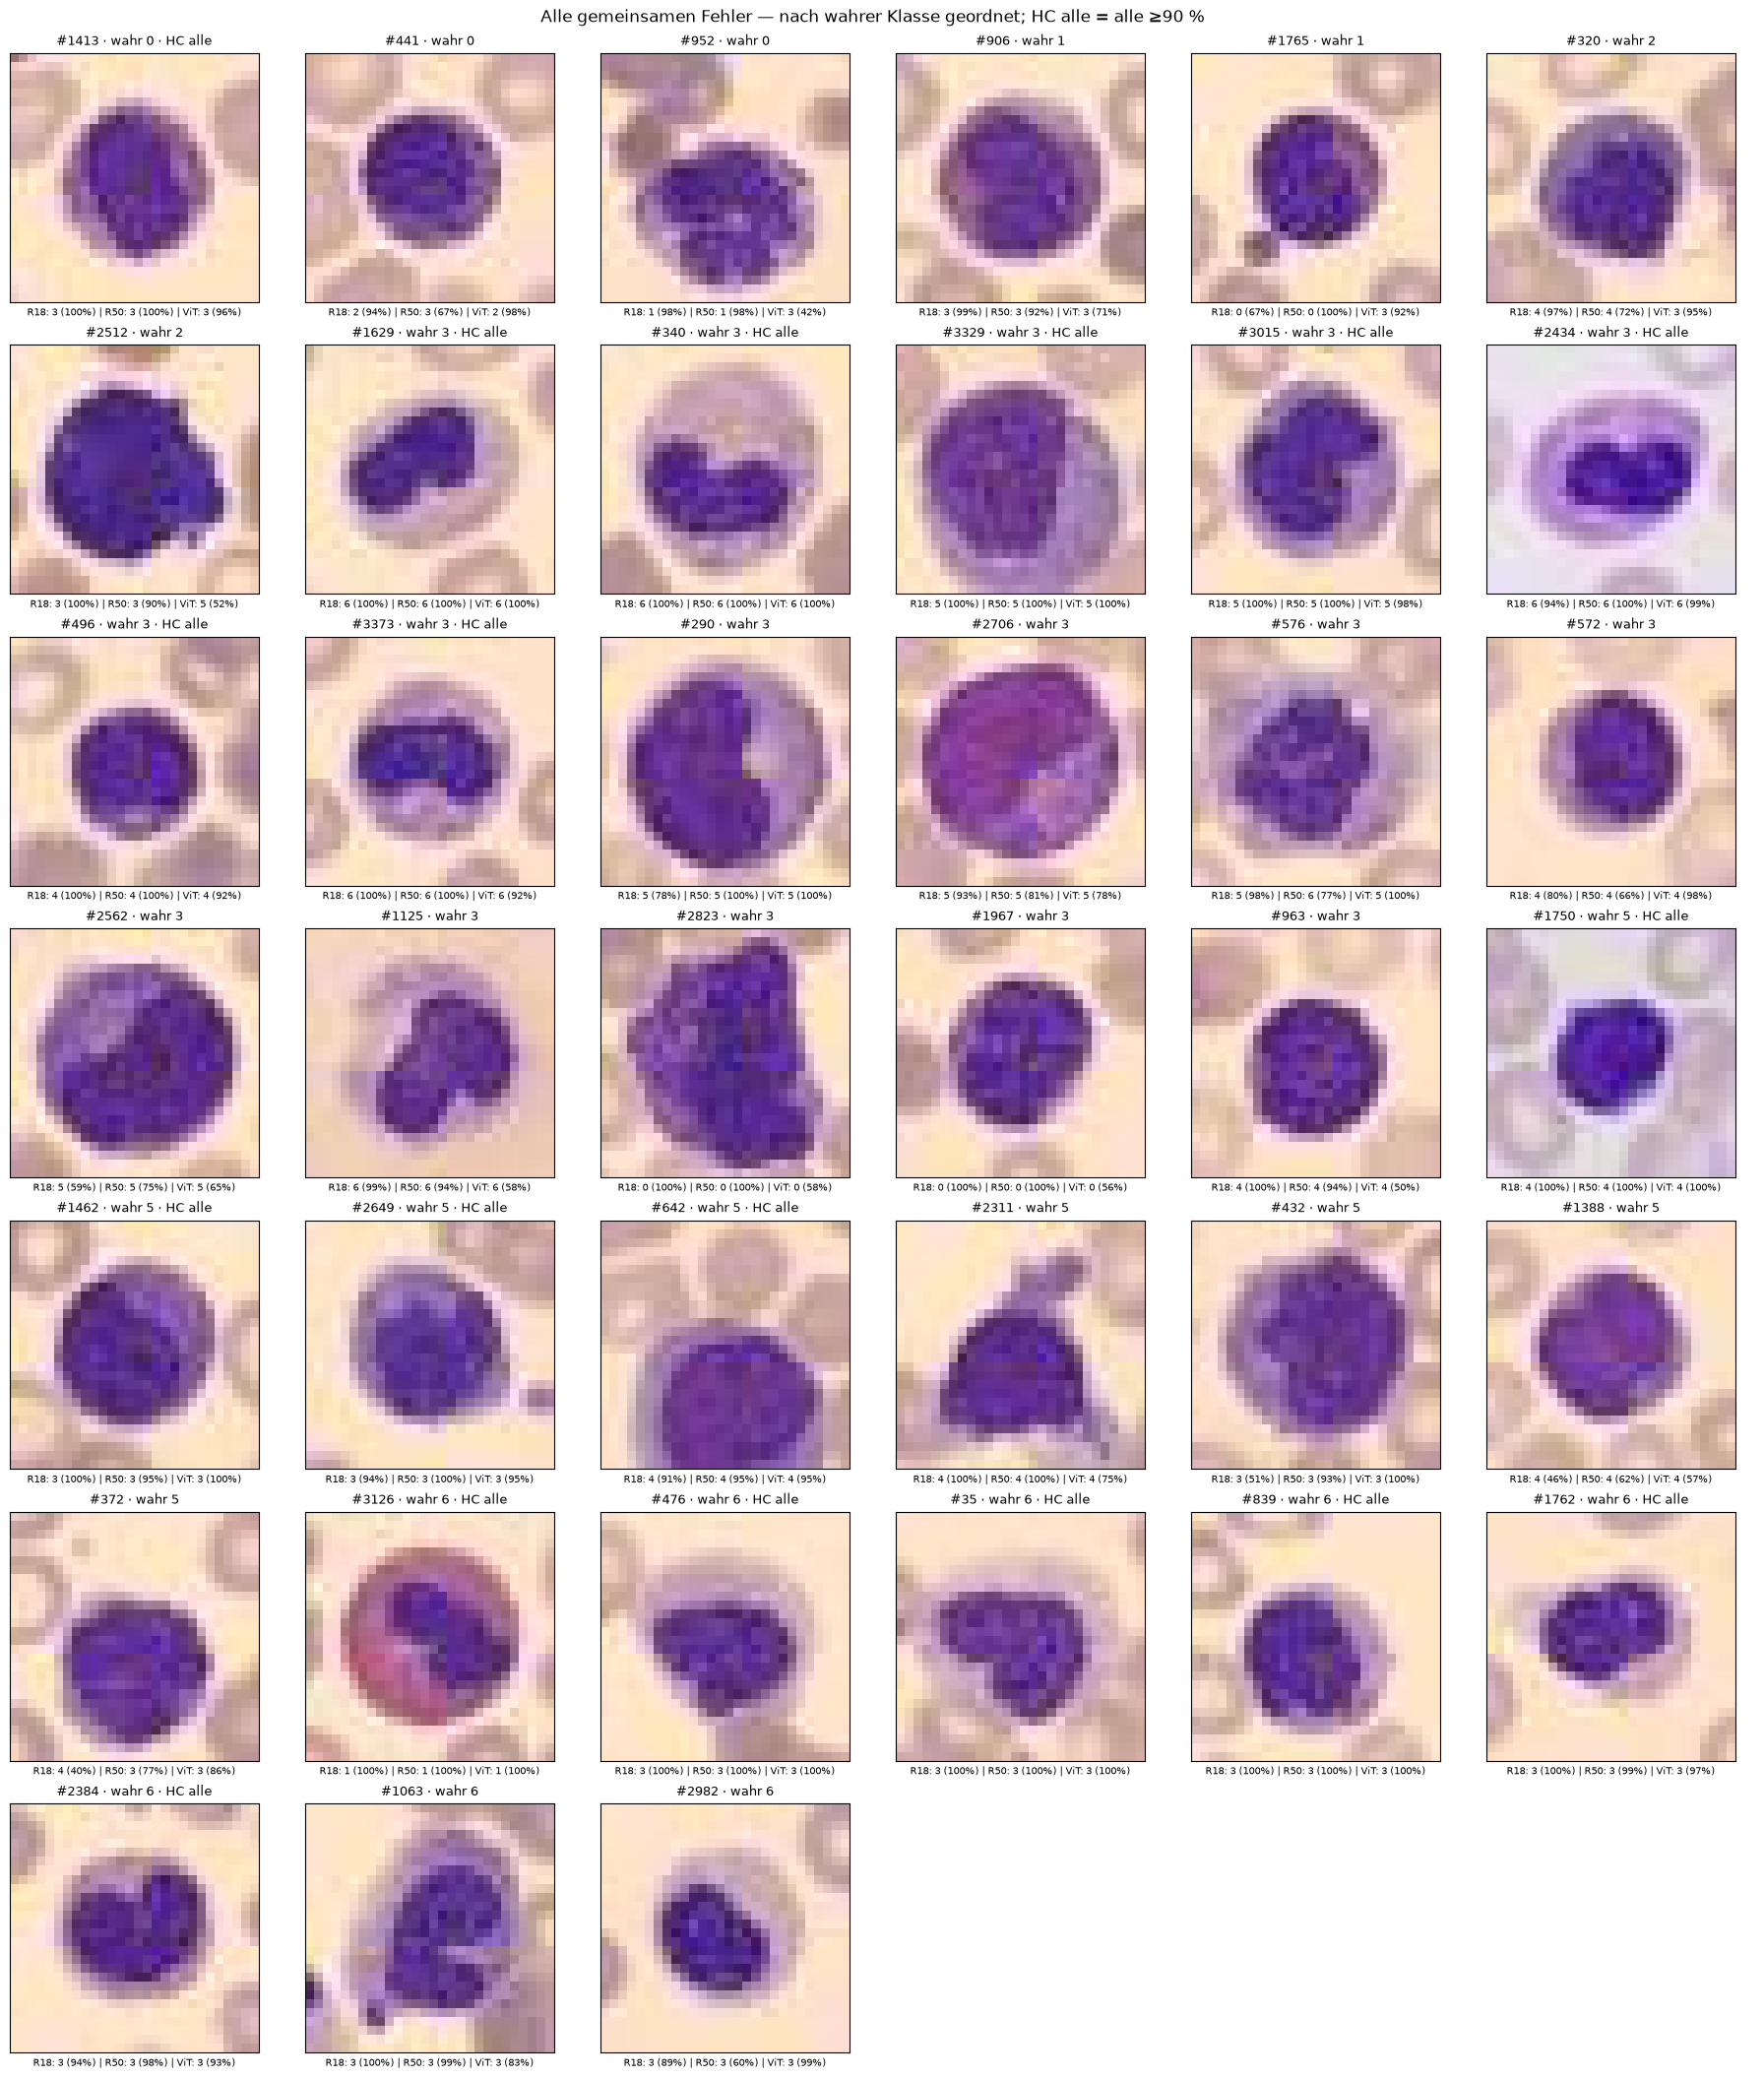

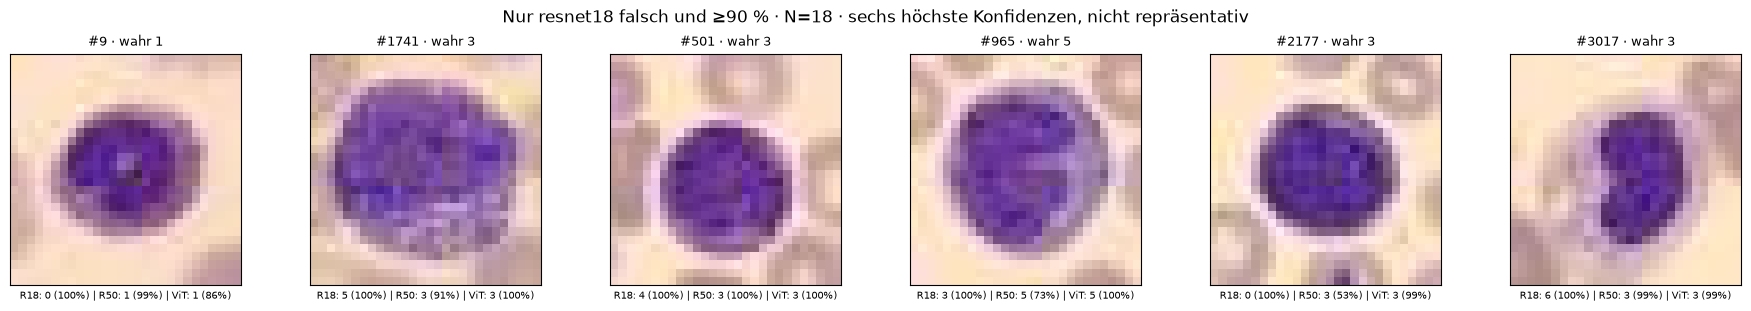

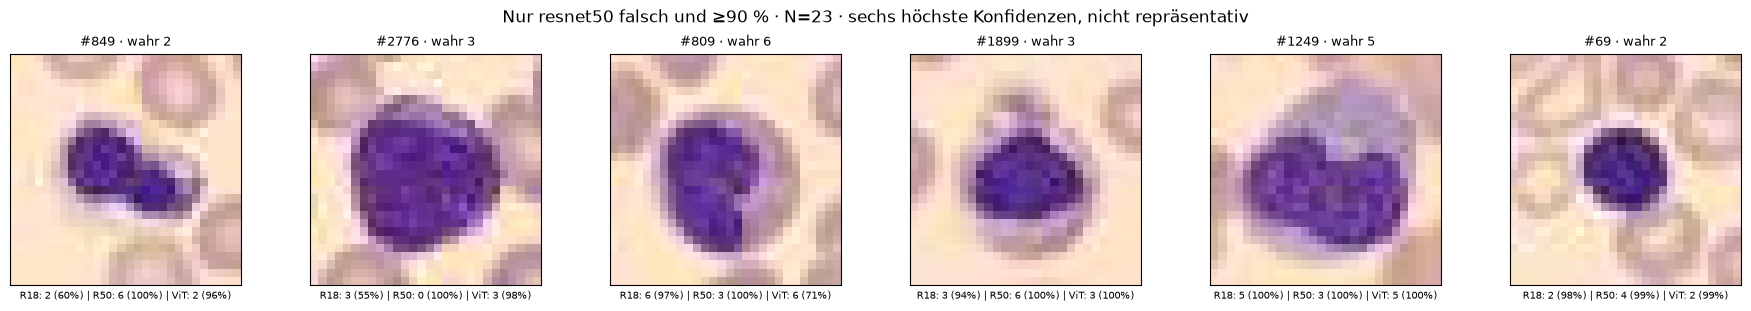

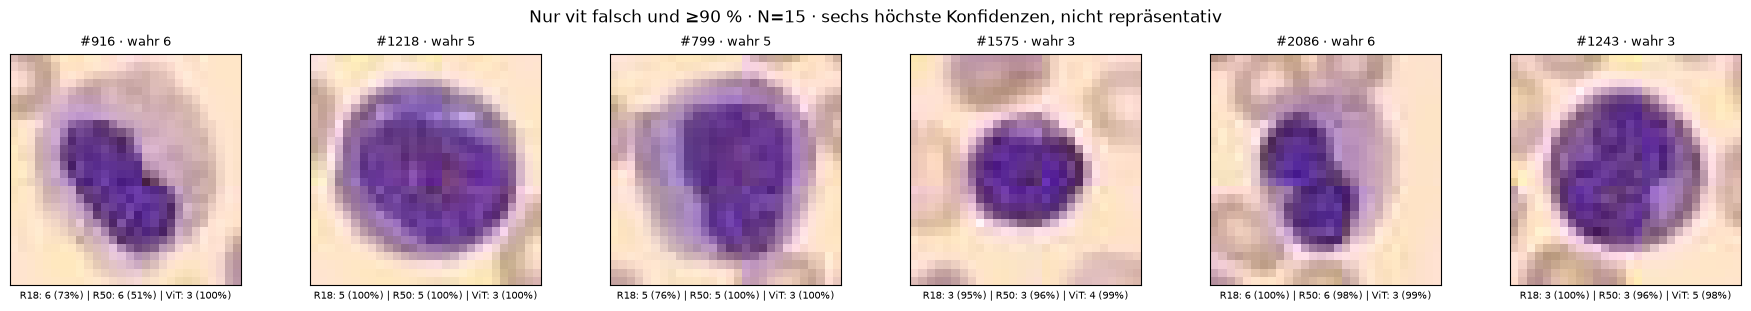

In [18]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Gemeinsame Fehler:', len(common_wrong), 'davon bei allen ≥90 %:', len(common_hc))
print('Klassen:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · wahr {labels[i]}' + (' · HC alle' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'Alle gemeinsamen Fehler — nach wahrer Klasse geordnet; HC alle = alle ≥90 %')
for m, ids in enumerate(exclusive_hc):
    chosen = ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
    gallery(chosen, f'Nur {model_names[m]} falsch und ≥90 % · N={len(ids)} · sechs höchste Konfidenzen, nicht repräsentativ')

## A · Direkter Bildvergleich — Fehler neben ähnlicher, in allen Modellen korrekt und ≥90 % klassifizierter Kontrolle derselben wahren Klasse

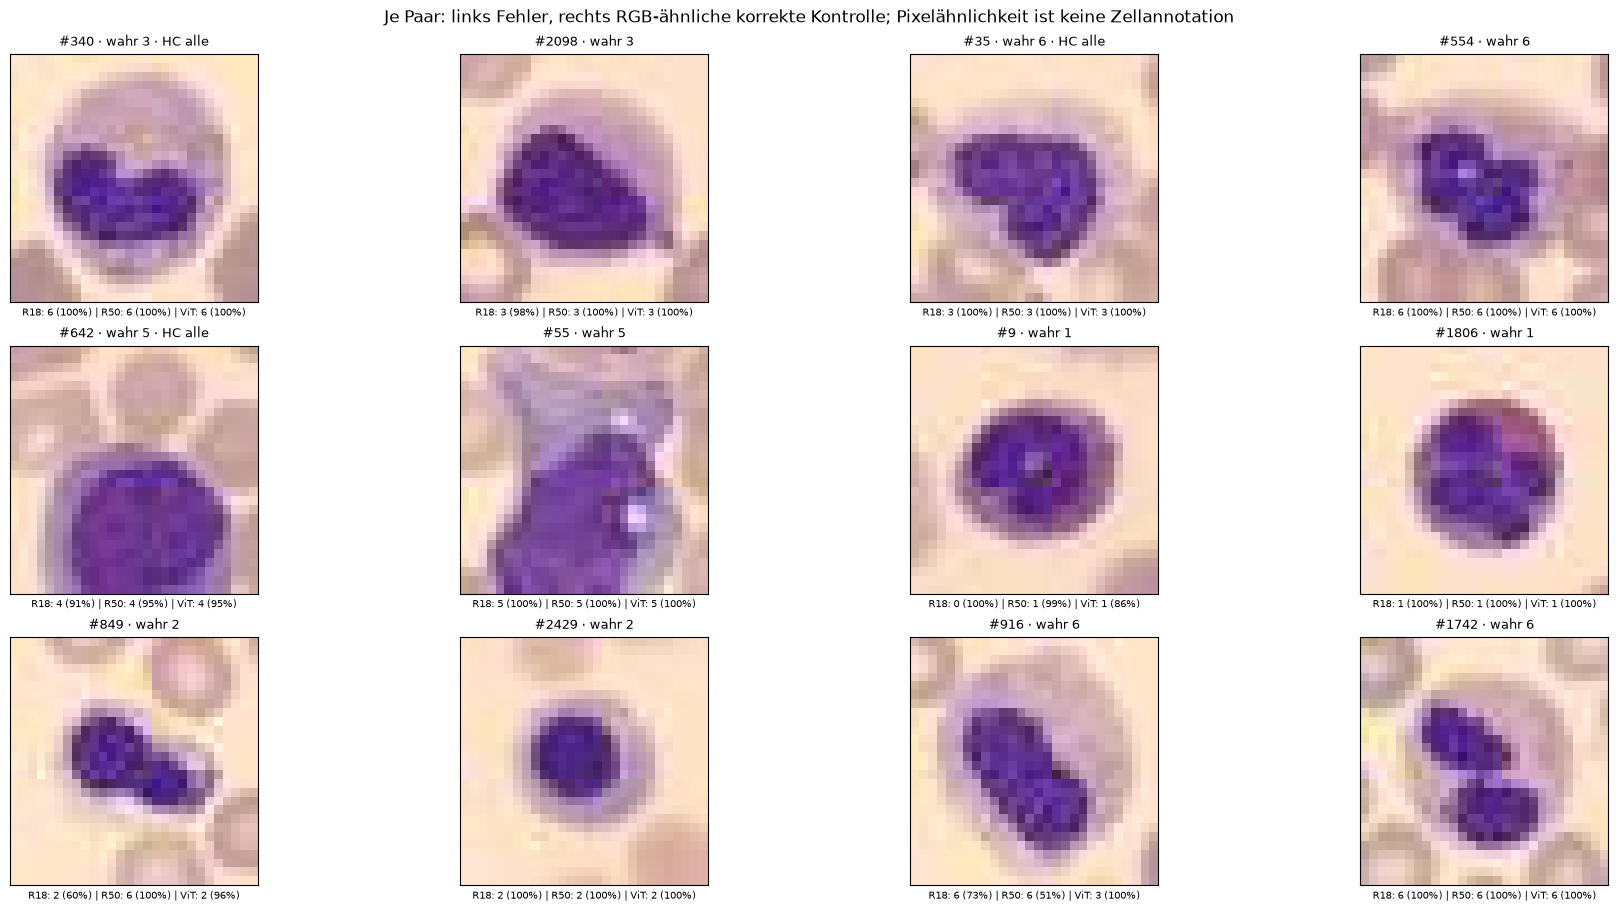

In [19]:
clean = correct.all(0) & (confidence >= threshold).all(0)
largest_classes = np.argsort(-np.bincount(labels[common_hc], minlength=8))[:3]
selected_errors = [common_hc[labels[common_hc] == c][0] for c in largest_classes if (labels[common_hc] == c).any()]
selected_errors += [ids[np.argmax(confidence[m, ids])] for m, ids in enumerate(exclusive_hc) if len(ids)]
gallery_pairs = []
for i in selected_errors:
    allowed = clean & (labels == labels[i])
    assert allowed.any()
    distance = squared + squared[i] - 2 * flat @ flat[i]
    control = np.where(allowed, distance, np.inf).argmin()
    gallery_pairs.append([i, control])
gallery_pairs = np.array(gallery_pairs)
gallery(gallery_pairs.ravel(), 'Je Paar: links Fehler, rechts RGB-ähnliche korrekte Kontrolle; Pixelähnlichkeit ist keine Zellannotation', columns=4)

## B · Hypothesen: Klassenhäufung und Bildmerkmale — Fehlerrate je wahrer Klasse; Bildmerkmale gegen klassenangepasste, in allen Modellen korrekt-konfidente Kontrollen

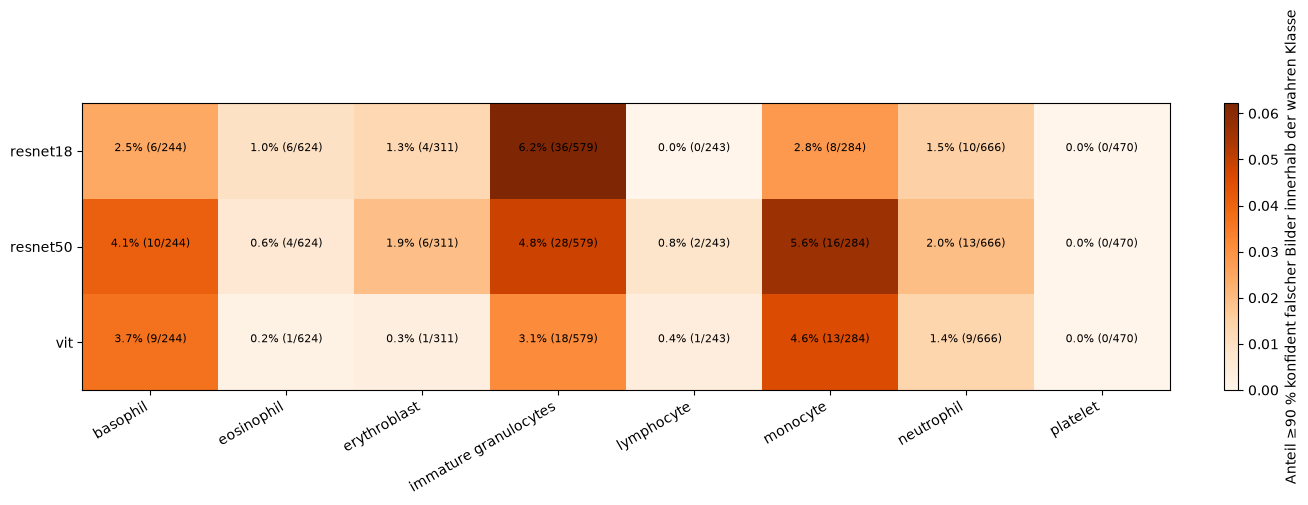

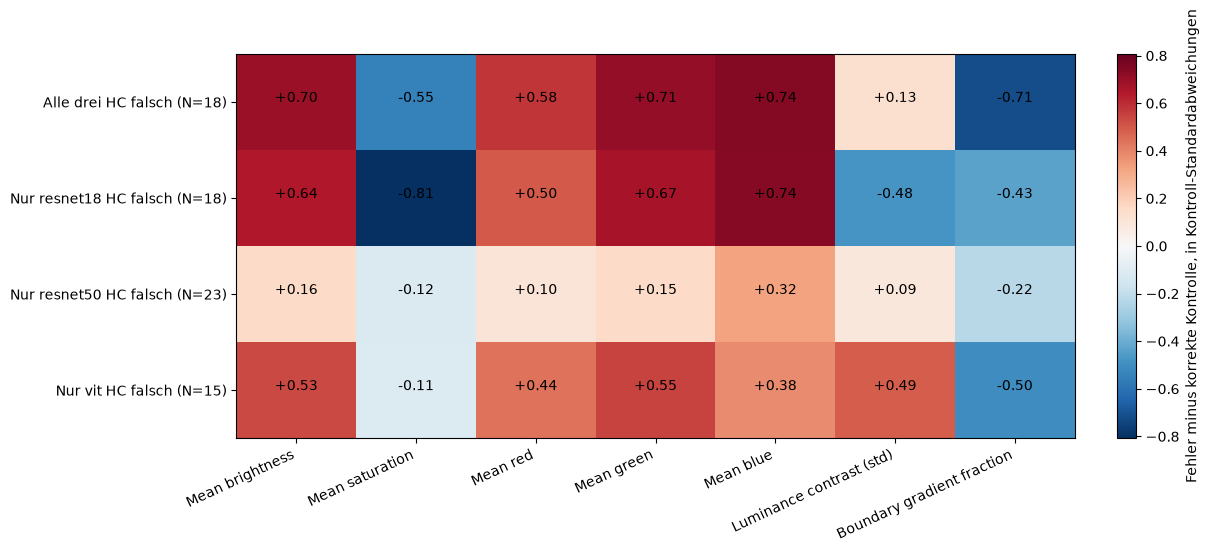

In [20]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for m in range(3):
    for c in range(8):
        ax.text(c, m, f'{class_hc_rates[m, c]:.1%} ({class_hc_counts[m, c]}/{class_sizes[c]})', ha='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Anteil ≥90 % konfident falscher Bilder innerhalb der wahren Klasse')
plt.show()

cohorts = [common_hc, *exclusive_hc]
cohort_names = ['Alle drei HC falsch', *[f'Nur {name} HC falsch' for name in model_names]]
cohort_effects, cohort_weights = [], []
for ids in cohorts:
    weights = np.zeros(len(labels))
    for c in np.unique(labels[ids]):
        mask = clean & (labels == c)
        assert mask.any()
        weights[mask] = (labels[ids] == c).mean() / mask.sum()
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    cohort_effects.append((features[ids].mean(0) - mean) / np.maximum(std, 1e-12))
    cohort_weights.append(weights)
cohort_effects = np.stack(cohort_effects)
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
limit = max(np.abs(cohort_effects).max(), 0.01)
im = ax.imshow(cohort_effects, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set(xticks=range(7), xticklabels=feature_names, yticks=range(4),
       yticklabels=[f'{name} (N={len(ids)})' for name, ids in zip(cohort_names, cohorts)])
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
for row in range(4):
    for col in range(7):
        ax.text(col, row, f'{cohort_effects[row, col]:+.2f}', ha='center')
fig.colorbar(im, ax=ax, label='Fehler minus korrekte Kontrolle, in Kontroll-Standardabweichungen')
plt.show()

## C · Stability-Verknüpfung — gleiche Helligkeits- und Translationsstufen, alle HC-Fehler und RGB-nahe korrekte ≥90%-Kontrollen derselben Klasse; Änderung der ursprünglichen Entscheidung ist nicht automatisch Korrektur

resnet18: 70 Fehler, 67 verschiedene Kontrollen; mittlere Ausgangskonfidenz 97.6% / 99.6%


resnet18 brightness: mittlerer Wahrscheinlichkeitsverlust Fehler 0.528, Kontrollen 0.370


resnet18 translation: mittlerer Wahrscheinlichkeitsverlust Fehler 0.390, Kontrollen 0.120
resnet50: 79 Fehler, 75 verschiedene Kontrollen; mittlere Ausgangskonfidenz 97.9% / 99.2%


resnet50 brightness: mittlerer Wahrscheinlichkeitsverlust Fehler 0.356, Kontrollen 0.298


resnet50 translation: mittlerer Wahrscheinlichkeitsverlust Fehler 0.369, Kontrollen 0.197


vit: 52 Fehler, 50 verschiedene Kontrollen; mittlere Ausgangskonfidenz 97.0% / 99.4%


vit brightness: mittlerer Wahrscheinlichkeitsverlust Fehler 0.105, Kontrollen 0.028


vit translation: mittlerer Wahrscheinlichkeitsverlust Fehler 0.078, Kontrollen 0.033


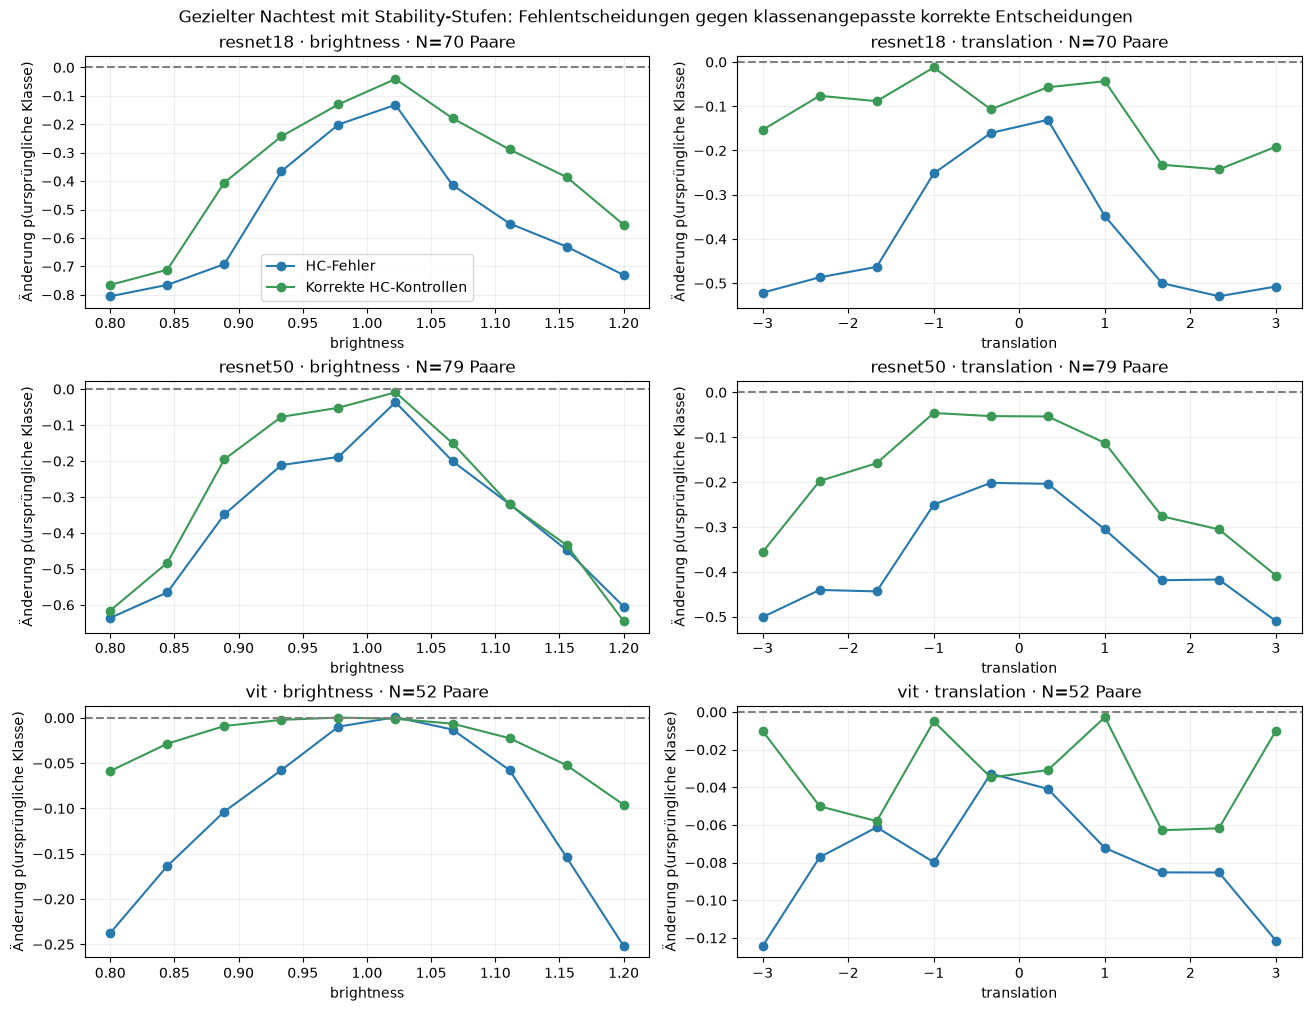

In [21]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    followup_levels = {kind: saved[f'levels_{kind}'] for kind in ['brightness', 'translation']}
followup = dict(model_names=model_names, threshold=threshold, common_wrong=common_wrong, common_hc=common_hc,
                gallery_pairs=gallery_pairs, class_sizes=class_sizes, class_hc_counts=class_hc_counts,
                cohort_names=cohort_names, cohort_effects=cohort_effects, cohort_weights=np.stack(cohort_weights),
                cohort_roles=['HC errors', 'correct HC controls'], checkpoints=checkpoints)
fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout='constrained')
for m, ids in enumerate(error_ids):
    distance = np.maximum(squared[:, None] + squared[ids][None] - 2 * flat @ flat[ids].T, 0)
    allowed = correct[m, :, None] & (confidence[m, :, None] >= threshold) & (labels[:, None] == labels[ids])
    assert allowed.any(0).all()
    controls = np.where(allowed, distance, np.inf).argmin(0)
    selected = np.stack((ids, controls))
    base, scores = predict(m, images[selected.ravel()])
    base = base.reshape(2, len(ids), 8)
    np.testing.assert_allclose(base, probabilities[m, selected], atol=1e-5, rtol=1e-4)
    original = base.argmax(-1)
    original_probability = base.max(-1)
    followup[f'{model_names[m]}_ids'] = selected
    followup[f'{model_names[m]}_exclusive_hc'] = exclusive_hc[m]
    followup[f'{model_names[m]}_baseline'] = base
    followup[f'{model_names[m]}_baseline_logits'] = scores.reshape(2, len(ids), 8)
    print(f'{model_names[m]}: {len(ids)} Fehler, {len(np.unique(controls))} verschiedene Kontrollen; mittlere Ausgangskonfidenz {original_probability[0].mean():.1%} / {original_probability[1].mean():.1%}')
    for col, (kind, values) in enumerate(followup_levels.items()):
        results, logits = [], []
        for value in values:
            changed = []
            for image in images[selected.ravel()]:
                pil = Image.fromarray(image)
                out = ImageEnhance.Brightness(pil).enhance(float(value)) if kind == 'brightness' else pil.transform(
                    pil.size, Image.Transform.AFFINE, (1, 0, -float(value), 0, 1, 0),
                    resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
                changed.append(np.asarray(out))
            p, scores = predict(m, np.stack(changed))
            results.append(p.reshape(2, len(ids), 8))
            logits.append(scores.reshape(2, len(ids), 8))
        p = np.stack(results, axis=1)
        delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
        followup[f'{model_names[m]}_{kind}'] = p
        followup[f'{model_names[m]}_{kind}_logits'] = np.stack(logits, axis=1)
        for role, name in enumerate(['HC-Fehler', 'Korrekte HC-Kontrollen']):
            axes[m, col].plot(values, delta[role].mean(-1), 'o-', label=name)
        axes[m, col].axhline(0, color='gray', ls='--')
        axes[m, col].set(title=f'{model_names[m]} · {kind} · N={len(ids)} Paare',
                          xlabel=kind, ylabel='Änderung p(ursprüngliche Klasse)')
        axes[m, col].grid(alpha=0.2)
        print(f'{model_names[m]} {kind}: mittlerer Wahrscheinlichkeitsverlust Fehler {-delta[0].mean():.3f}, Kontrollen {-delta[1].mean():.3f}')
axes[0, 0].legend()
fig.suptitle('Gezielter Nachtest mit Stability-Stufen: Fehlentscheidungen gegen klassenangepasste korrekte Entscheidungen')
plt.show()
followup.update({f'levels_{kind}': values for kind, values in followup_levels.items()})
np.savez_compressed('predictions/high_confidence_followup.npz', **followup)

## Findings

- **Gemeinsame Fehler (Galerie A):** 39 Bilder sind bei allen drei Modellen falsch, davon 18 überall ≥90 % konfident. Bei diesen 18 sagen alle dieselbe falsche Klasse voraus; 9 verwechseln immature granulocytes mit neutrophils oder umgekehrt.
- **Klassenabhängigkeit (Heatmap B):** ResNet18 hat bei immature granulocytes 6,22 % HC-Fehler, insgesamt 2,05 %. Bei beiden anderen Modellen sind monocytes am stärksten betroffen: ResNet50 5,63 %, ViT 4,58 %.
- **Bildmerkmale (Heatmap B):** Die 18 gemeinsamen HC-Fehler sind gegenüber klassenangepassten korrekten Kontrollen heller (+0,70 SD), haben höhere Blauwerte (+0,74 SD) und weniger Sättigung (−0,55 SD). Die Bildpaare zeigen ähnliche Farbflächen bei unterschiedlichen dunklen Teilstrukturen; das ersetzt keine Zellannotation.
- **Stability-Verknüpfung (Kurven C):** Bei Helligkeit und Translation verlieren Fehlentscheidungen in allen drei Modellen im Mittel stärker an Wahrscheinlichkeit als korrekte Kontrollen. Beispiel ResNet18, über die zehn Translationsstufen gemittelt: −39,0 gegenüber −12,0 Prozentpunkten für die ursprüngliche Klasse. Ein Wechsel ist nicht automatisch eine Korrektur.

**Grenzen:** Nur 18 gemeinsame HC-Fälle. Kontrollen sind klassen- und schwellenangepasst, aber nicht exakt konfidenzangepasst und teilweise mehrfach verwendet. ResNet18/ViT verarbeiten 224×224, ResNet50 28×28; auch die Resize-Verfahren unterscheiden sich. Farbe und Helligkeit hängen zusammen. Änderungen müssen Labels nicht erhalten. Die Befunde liefern Hypothesen, keine Ursachen; auf neuen Bildern prüfen.